# Penggabungan Data Susenas Maret 2025 dan September 2025
## Modul Konsumsi dan Pengeluaran — Provinsi NTB

Notebook ini menggabungkan dua periode pencacahan Susenas 2025 (Maret dan September) menjadi satu dataset, dengan penyesuaian nama kolom terlebih dahulu karena kedua periode menggunakan penamaan variabel yang sedikit berbeda.

**Catatan penting:** Maret dan September adalah **dua sampel rumah tangga yang berbeda** (bukan rumah tangga yang sama disurvei dua kali), sehingga penggabungan ini bersifat menambah jumlah observasi, bukan membentuk data panel/longitudinal. Kolom `periode` ditambahkan agar hal ini tetap tercatat secara transparan.

**Alur notebook:**
1. Upload kedua file data
2. Baca & tampilkan struktur masing-masing file
3. Samakan nama kolom (September → standar Maret)
4. Tambahkan penanda periode
5. Gabungkan kedua data
6. Validasi hasil penggabungan
7. Ekspor hasil akhir


## 1. Setup & Upload Data

Upload kedua file Susenas Modul Konsumsi (Maret dan September). Mendukung format `.csv`, `.xlsx`, atau `.dbf`.

In [ ]:
# Install library pendukung (untuk baca file .dbf, jika diperlukan)
!pip install dbfread simpledbf -q

import pandas as pd
import numpy as np
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
print('Library siap.')

  Preparing metadata (setup.py) ... done
Library siap.


In [ ]:
def baca_file(path):
    """Baca file otomatis sesuai ekstensinya (csv, xlsx, dbf)."""
    if path.lower().endswith('.csv'):
        return pd.read_csv(path)
    elif path.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path)
    elif path.lower().endswith('.dbf'):
        from dbfread import DBF
        table = DBF(path, encoding='latin1')
        return pd.DataFrame(iter(table))
    else:
        raise ValueError(f"Format file tidak dikenali: {path}")

print("Silakan upload file Susenas MARET 2025 (Modul Konsumsi dan Pengeluaran)")
uploaded_maret = files.upload()
file_maret = list(uploaded_maret.keys())[0]
df_maret = baca_file(file_maret)
print(f"\nFile Maret berhasil dibaca: {df_maret.shape[0]} baris, {df_maret.shape[1]} kolom")

Silakan upload file Susenas MARET 2025 (Modul Konsumsi dan Pengeluaran)


Saving data susenas maret 2025 modul konsumsi dan pengeluaran.xlsx to data susenas maret 2025 modul konsumsi dan pengeluaran.xlsx

File Maret berhasil dibaca: 7108 baris, 20 kolom


In [ ]:
print("Silakan upload file Susenas SEPTEMBER 2025 (Modul Konsumsi dan Pengeluaran)")
uploaded_sept = files.upload()
file_sept = list(uploaded_sept.keys())[0]
df_sept = baca_file(file_sept)
print(f"\nFile September berhasil dibaca: {df_sept.shape[0]} baris, {df_sept.shape[1]} kolom")

Silakan upload file Susenas SEPTEMBER 2025 (Modul Konsumsi dan Pengeluaran)


Saving data susenas september 2025 modul konsumsi dan pengeluaran.xlsx to data susenas september 2025 modul konsumsi dan pengeluaran.xlsx

File September berhasil dibaca: 1576 baris, 19 kolom


## 2. Cek Struktur Awal Kedua Data

Sebelum digabung, cek dulu nama kolom masing-masing file untuk memastikan variabel yang tersedia sesuai perkiraan.

In [ ]:
print("=== KOLOM DATA MARET ===")
print(sorted(df_maret.columns.tolist()))
print(f"\nJumlah kolom: {len(df_maret.columns)}")

print("\n=== KOLOM DATA SEPTEMBER ===")
print(sorted(df_sept.columns.tolist()))
print(f"\nJumlah kolom: {len(df_sept.columns)}")

=== KOLOM DATA MARET ===
['EXPEND', 'FOOD', 'KABU', 'KALORI_KAP', 'KAPITA', 'KARBO_KAP', 'LEMAK_KAP', 'NONFOOD', 'PROTE_KAP', 'PSU', 'R101', 'R102', 'R105', 'R203', 'R301', 'SSU', 'STRATA', 'URUT', 'WEIND', 'WERT']

Jumlah kolom: 20

=== KOLOM DATA SEPTEMBER ===
['CAL', 'CARB', 'EXPEND', 'FAT', 'FOOD', 'KAPITA', 'M101', 'M102', 'M105', 'M203', 'M301', 'NONFOOD', 'PROT', 'PSU', 'SSU', 'STRATA', 'URUT', 'WEIND', 'WERT']

Jumlah kolom: 19


### Kamus Variabel Susenas Maret 2025 (Berdasarkan Sistem Informasi Layanan Statistik BPS)

* **EXPEND**: Rata-rata pengeluaran rumah tangga sebulan (Rupiah).
* **FOOD**: Rata-rata pengeluaran makanan rumah tangga sebulan (Rupiah).
* **NONFOOD**: Rata-rata pengeluaran bukan makanan rumah tangga sebulan (Rupiah).
* **KAPITA**: Rata-rata pengeluaran per kapita sebulan (Rupiah).
* **KALORI_KAP**: Banyaknya konsumsi kalori per kapita sehari (Kkal).
* **PROTE_KAP**: Banyaknya konsumsi protein per kapita sehari (Gram).
* **KARBO_KAP**: Banyaknya konsumsi karbohidrat per kapita sehari (Gram).
* **LEMAK_KAP**: Banyaknya konsumsi lemak per kapita sehari (Gram).
* **R101**: Provinsi (Kode Provinsi Nusa Tenggara Barat).
* **R102**: Kabupaten/Kota (Kode wilayah kabupaten/kota di NTB).
* **R105**: Klasifikasi desa/kelurahan (Perkotaan / Perdesaan).
* **R203**: Hasil pencacahan rumah tangga / jenis kelamin.
* **R301**: Jumlah anggota rumah tangga (ART).
* **PSU**: *Primary Sampling Unit* (Blok Sensus).
* **SSU**: *Secondary Sampling Unit* (Segment).
* **STRATA**: Strata pencacahan wilayah.
* **URUT**: Nomor urut rumah tangga.
* **WEIND**: Penimbang untuk estimasi penduduk.
* **WERT**: Penimbang untuk estimasi rumah tangga.
* **KABU**: Kabupaten/kota (variabel administratif tambahan).

### Kamus Variabel Susenas September 2025 (Berdasarkan Sistem Informasi Layanan Statistik BPS)

* **EXPEND**: Rata-rata pengeluaran rumah tangga sebulan (Rupiah).
* **FOOD**: Rata-rata pengeluaran makanan rumah tangga sebulan (Rupiah).
* **NONFOOD**: Rata-rata pengeluaran bukan makanan rumah tangga sebulan (Rupiah).
* **KAPITA**: Rata-rata pengeluaran per kapita sebulan (Rupiah).
* **CAL** (disetarakan ke `KALORI_KAP`): Banyaknya konsumsi kalori per kapita sehari (Kkal).
* **PROT** (disetarakan ke `PROTE_KAP`): Banyaknya konsumsi protein per kapita sehari (Gram).
* **CARB** (disetarakan ke `KARBO_KAP`): Banyaknya konsumsi karbohidrat per kapita sehari (Gram).
* **FAT** (disetarakan ke `LEMAK_KAP`): Banyaknya konsumsi lemak per kapita sehari (Gram).
* **M101** (disetarakan ke `R101`): Provinsi.
* **M102** (disetarakan ke `R102`): Kabupaten/Kota.
* **M105** (disetarakan ke `R105`): Klasifikasi desa/kelurahan (Perkotaan / Perdesaan).
* **M203** (disetarakan ke `R203`): Hasil pencacahan rumah tangga / jenis kelamin.
* **M301** (disetarakan ke `R301`): Jumlah anggota rumah tangga (ART).
* **PSU**: *Primary Sampling Unit*.
* **SSU**: *Secondary Sampling Unit*.
* **STRATA**: Strata pencacahan wilayah.
* **URUT**: Nomor urut rumah tangga.
* **WEIND**: Penimbang untuk estimasi penduduk.
* **WERT**: Penimbang untuk estimasi rumah tangga.

In [ ]:
print("=== 5 BARIS PERTAMA - MARET ===")
display(df_maret.head())

print("\n=== 5 BARIS PERTAMA - SEPTEMBER ===")
display(df_sept.head())

=== 5 BARIS PERTAMA - MARET ===


,EXPEND,FOOD,KABU,KALORI_KAP,KAPITA,KARBO_KAP,LEMAK_KAP,NONFOOD,PROTE_KAP,PSU,R101,R102,R105,R203,R301,SSU,STRATA,URUT,WEIND,WERT
0,4469248,2495957,5204,2152,1117312,347,37,1973291,71,79425,52,4,1,1,4,483302,2584,175005,2660,665
1,1075628,712628,5202,3277,1075628,555,52,363000,90,80700,52,2,1,1,1,36444,3949,175012,63,63
2,3128952,1906285,5201,2474,1042984,397,43,1222666,65,62804,52,1,2,1,3,419309,2963,175015,2319,773
3,2772416,1767000,5201,2109,924138,290,39,1005416,74,72168,52,1,1,1,3,308686,3213,175022,654,218
4,13961416,6474000,5207,3670,6980708,522,88,7487416,103,30251,52,7,2,1,2,182448,2283,175049,61,30



=== 5 BARIS PERTAMA - SEPTEMBER ===


,CAL,CARB,EXPEND,FAT,FOOD,KAPITA,M101,M102,M105,M203,M301,NONFOOD,PROT,PSU,SSU,STRATA,URUT,WEIND,WERT
0,2277,362,3081605,46,1700271,1027202,52,5,1,1,3,1381333,76,5550,76831,3753,138,929,310
1,3145,419,6584631,74,3967714,6584631,52,7,1,1,1,2616917,140,1937,76708,3806,261,45,45
2,2201,277,2287736,40,1081286,1143868,52,72,1,1,2,1206450,71,3368,76701,3157,268,337,169
3,3376,490,3442607,50,2475857,1147536,52,2,1,1,3,966750,94,4839,76680,3732,290,1911,637
4,2435,245,11263917,69,5163000,3754639,52,7,1,1,3,6100917,121,1937,76663,3806,306,25,8


## 3. Penyesuaian Nama Kolom (Standarisasi)

Beberapa variabel punya nama berbeda antara Maret dan September meski isinya sama. Kolom di data **September** disesuaikan mengikuti penamaan standar di data **Maret**.

| September | Disesuaikan Menjadi (Maret) | Isi |
|---|---|---|
| M101 | R101 | Provinsi |
| M102 | R102 | Kabupaten/Kota |
| M105 | R105 | Klasifikasi Desa/Kelurahan |
| M203 | R203 | Hasil Pencacahan Rumah Tangga |
| M301 | R301 | Jumlah Anggota Rumah Tangga |
| CAL | KALORI_KAP | Konsumsi Kalori per Kapita Sehari |
| CARB | KARBO_KAP | Konsumsi Karbohidrat per Kapita Sehari |
| FAT | LEMAK_KAP | Konsumsi Lemak per Kapita Sehari |
| PROT | PROTE_KAP | Konsumsi Protein per Kapita Sehari |


In [ ]:
# Mapping penyesuaian nama kolom (September -> Maret)
mapping_kolom = {
    'M101': 'R101',
    'M102': 'R102',
    'M105': 'R105',
    'M203': 'R203',
    'M301': 'R301',
    'CAL': 'KALORI_KAP',
    'CARB': 'KARBO_KAP',
    'FAT': 'LEMAK_KAP',
    'PROT': 'PROTE_KAP',
}

# Cek dulu mana yang benar-benar ada di data September (jaga-jaga kalau ada penamaan lain)
mapping_aktif = {k: v for k, v in mapping_kolom.items() if k in df_sept.columns}
tidak_ditemukan = [k for k in mapping_kolom if k not in df_sept.columns]

print("Kolom yang akan di-rename:")
for k, v in mapping_aktif.items():
    print(f"  {k}  ->  {v}")

if tidak_ditemukan:
    print(f"\n⚠️ Kolom berikut TIDAK ditemukan di data September, cek manual: {tidak_ditemukan}")

df_sept_renamed = df_sept.rename(columns=mapping_aktif)
print("\n✅ Rename selesai.")

Kolom yang akan di-rename:
  M101  ->  R101
  M102  ->  R102
  M105  ->  R105
  M203  ->  R203
  M301  ->  R301
  CAL  ->  KALORI_KAP
  CARB  ->  KARBO_KAP
  FAT  ->  LEMAK_KAP
  PROT  ->  PROTE_KAP

✅ Rename selesai.


In [ ]:
# Bandingkan kolom kedua data setelah rename - cek mana yang cocok, mana yang beda
kolom_maret = set(df_maret.columns)
kolom_sept = set(df_sept_renamed.columns)

kolom_sama = kolom_maret & kolom_sept
hanya_maret = kolom_maret - kolom_sept
hanya_sept = kolom_sept - kolom_maret

print(f"Kolom yang SAMA di kedua data ({len(kolom_sama)}): {sorted(kolom_sama)}")
print(f"\nKolom HANYA ada di Maret ({len(hanya_maret)}): {sorted(hanya_maret)}")
print(f"\nKolom HANYA ada di September ({len(hanya_sept)}): {sorted(hanya_sept)}")

print("\nCatatan: kolom yang hanya ada di salah satu data akan tetap dipertahankan setelah")
print("digabung, tapi nilainya akan kosong (NaN) untuk baris dari periode yang tidak punya kolom itu.")

Kolom yang SAMA di kedua data (19): ['EXPEND', 'FOOD', 'KALORI_KAP', 'KAPITA', 'KARBO_KAP', 'LEMAK_KAP', 'NONFOOD', 'PROTE_KAP', 'PSU', 'R101', 'R102', 'R105', 'R203', 'R301', 'SSU', 'STRATA', 'URUT', 'WEIND', 'WERT']

Kolom HANYA ada di Maret (1): ['KABU']

Kolom HANYA ada di September (0): []

Catatan: kolom yang hanya ada di salah satu data akan tetap dipertahankan setelah
digabung, tapi nilainya akan kosong (NaN) untuk baris dari periode yang tidak punya kolom itu.


### Tabel Perbandingan dan Penyepadanan Kamus Variabel Susenas 2025 (BPS)

| No. | Variabel Maret 2025 | Variabel September 2025 | Nama Variabel Terstandarisasi | Keterangan & Label Resmi BPS | Tipe Data |
|---|---|---|---|---|---|
| 1 | `EXPEND` | `EXPEND` | `EXPEND` | Rata-rata pengeluaran rumah tangga sebulan (Rupiah) | Numeric |
| 2 | `FOOD` | `FOOD` | `FOOD` | Rata-rata pengeluaran makanan rumah tangga sebulan (Rupiah) | Numeric |
| 3 | `NONFOOD` | `NONFOOD` | `NONFOOD` | Rata-rata pengeluaran bukan makanan rumah tangga sebulan (Rupiah) | Numeric |
| 4 | `KAPITA` | `KAPITA` | `KAPITA` | Rata-rata pengeluaran per kapita sebulan (Rupiah) | Numeric |
| 5 | `KALORI_KAP` | `CAL` | `KALORI_KAP` | Banyaknya konsumsi kalori per kapita sehari (Kkal) | Numeric |
| 6 | `PROTE_KAP` | `PROT` | `PROTE_KAP` | Banyaknya konsumsi protein per kapita sehari (Gram) | Numeric |
| 7 | `KARBO_KAP` | `CARB` | `KARBO_KAP` | Banyaknya konsumsi karbohidrat per kapita sehari (Gram) | Numeric |
| 8 | `LEMAK_KAP` | `FAT` | `LEMAK_KAP` | Banyaknya konsumsi lemak per kapita sehari (Gram) | Numeric |
| 9 | `R101` | `M101` | `R101` | Kode Provinsi (Provinsi Nusa Tenggara Barat) | Numeric |
| 10 | `R102` | `M102` | `R102` | Kode Kabupaten/Kota | Numeric |
| 11 | `R105` | `M105` | `R105` | Klasifikasi desa/kelurahan (1 = Perkotaan, 2 = Perdesaan) | Numeric |
| 12 | `R203` | `M203` | `R203` | Hasil pencacahan rumah tangga | Numeric |
| 13 | `R301` | `M301` | `R301` | Jumlah anggota rumah tangga (ART) | Numeric |
| 14 | `PSU` | `PSU` | `PSU` | *Primary Sampling Unit* (Blok Sensus) | Numeric |
| 15 | `SSU` | `SSU` | `SSU` | *Secondary Sampling Unit* (Segment) | Numeric |
| 16 | `STRATA` | `STRATA` | `STRATA` | Strata pencacahan wilayah | Numeric |
| 17 | `URUT` | `URUT` | `URUT` | Nomor urut rumah tangga sampel | Numeric |
| 18 | `WEIND` | `WEIND` | `WEIND` | Penimbang untuk estimasi penduduk | Numeric |
| 19 | `WERT` | `WERT` | `WERT` | Penimbang untuk estimasi rumah tangga | Numeric |
| 20 | `KABU` | *-* | *(Dihapus)* | Kode Kabupaten/Kota pada data Maret (dihapus manual agar struktur kolom seragam) | Numeric |

**Catatan Penting Penyepadanan Data (Data Harmonization):**
* **Penghapusan Variabel `KABU`:** Variabel `KABU` hanya terdapat pada dataset periode Maret 2025 dan tidak ada pada periode September 2025. Variabel ini **dihapus secara manual** saat praproses data untuk menjamin kesetaraan jumlah dan struktur kolom antar kedua periode. Penghapusan ini **sangat aman dan tidak menghilangkan informasi wilayah**, karena informasi kode kabupaten/kota sudah terwakili secara mutlak oleh variabel `R102` (pada data Maret) dan `M102` (pada data September) yang isinya sama-sama memuat kode numerik kabupaten/kota resmi BPS.
* **Standarisasi Penamaan Variabel Gizi & Demografi:**
  * Beberapa variabel konsumsi gizi pada data September 2025 menggunakan kode singkatan internasional/Inggris (`CAL`, `PROT`, `CARB`, `FAT`), sehingga dilakukan *renaming* agar sesuai dengan penamaan data Maret 2025 (`KALORI_KAP`, `PROTE_KAP`, `KARBO_KAP`, `LEMAK_KAP`).
  * Kode blok wilayah dan demografi pada September 2025 yang diawali huruf `M` (`M101`, `M102`, `M105`, `M203`, `M301`) disetarakan dengan kode Maret 2025 yang diawali huruf `R` (`R101`, `R102`, `R105`, `R203`, `R301`).

##Kolom yang tidak ada di data september yaitu yang kolom "KABU" dan sudah saya hapus manual untuk kolom yang tersebut setalah datanya selesai digabungkan di unduh, penghapusan variabel yang KABU berisi kode kabupate dan kota ini tidak menjadi masalah karena masih ada kolom R102 yang sama-sama isinya kode kabupaten-kota di NTB

## Dan untuk yang filenya saya ubah manual dari csv ke xlcx

## 4. Tambahkan Penanda Periode

Ini penting untuk transparansi metodologi — supaya jelas bahwa data ini gabungan dua periode pencacahan berbeda, bukan data panel/longitudinal rumah tangga yang sama.

## Untuk yang kolom periode juga saya ubah manual dari Mar-25 menjadi 3 dan Sep-2025 menjadi 9

In [ ]:
df_maret = df_maret.copy()
df_sept_renamed = df_sept_renamed.copy()

df_maret['periode'] = 'Maret 2025'
df_sept_renamed['periode'] = 'September 2025'

print(f"Data Maret: {len(df_maret)} baris, ditandai periode 'Maret 2025'")
print(f"Data September: {len(df_sept_renamed)} baris, ditandai periode 'September 2025'")

Data Maret: 7108 baris, ditandai periode 'Maret 2025'
Data September: 1576 baris, ditandai periode 'September 2025'


## 5. Gabungkan Kedua Data

In [ ]:
df_gabungan = pd.concat([df_maret, df_sept_renamed], ignore_index=True, sort=False)

print(f"✅ Data berhasil digabungkan!")
print(f"   Total baris: {len(df_gabungan)}  ({len(df_maret)} Maret + {len(df_sept_renamed)} September)")
print(f"   Total kolom: {len(df_gabungan.columns)}")

print("\nDistribusi jumlah baris per periode:")
print(df_gabungan['periode'].value_counts())

✅ Data berhasil digabungkan!
   Total baris: 8684  (7108 Maret + 1576 September)
   Total kolom: 21

Distribusi jumlah baris per periode:
periode
Maret 2025        7108
September 2025    1576
Name: count, dtype: int64


## 6. Validasi Hasil Penggabungan

Beberapa pengecekan penting sebelum data ini dipakai untuk analisis lebih lanjut.

In [ ]:
# Cek missing value per kolom setelah digabung
print("=== CEK MISSING VALUE PER KOLOM ===")
missing = df_gabungan.isnull().sum()
missing_pct = (missing / len(df_gabungan) * 100).round(2)
missing_summary = pd.DataFrame({'jumlah_kosong': missing, 'persen_kosong': missing_pct})
missing_summary = missing_summary[missing_summary['jumlah_kosong'] > 0].sort_values('jumlah_kosong', ascending=False)

if len(missing_summary) == 0:
    print("✅ Tidak ada kolom dengan nilai kosong.")
else:
    print(missing_summary)
    print("\nCatatan: kolom dengan 100% kosong pada salah satu periode adalah wajar jika")
    print("variabel tersebut memang tidak tersedia di periode tersebut (lihat bagian 3).")

=== CEK MISSING VALUE PER KOLOM ===
      jumlah_kosong  persen_kosong
KABU           1576          18.15

Catatan: kolom dengan 100% kosong pada salah satu periode adalah wajar jika
variabel tersebut memang tidak tersedia di periode tersebut (lihat bagian 3).


In [ ]:
# Cek sebaran wilayah (Kabupaten/Kota di NTB) - pastikan kode R102 terbaca konsisten
print("=== SEBARAN JUMLAH RUMAH TANGGA PER KABUPATEN/KOTA & PERIODE ===")
if 'R102' in df_gabungan.columns:
    tabel_wilayah = pd.crosstab(df_gabungan['R102'], df_gabungan['periode'])
    tabel_wilayah['Total'] = tabel_wilayah.sum(axis=1)
    print(tabel_wilayah)
    print("\n⚠️ Perhatikan kabupaten/kota dengan jumlah sampel September yang sangat kecil —")
    print("ini perlu jadi catatan keterbatasan representativitas di laporan.")
else:
    print("Kolom R102 tidak ditemukan, cek ulang nama kolom kabupaten/kota.")

=== SEBARAN JUMLAH RUMAH TANGGA PER KABUPATEN/KOTA & PERIODE ===
periode  Maret 2025  September 2025  Total
R102                                      
1               800             180    980
2               870             200   1070
3               910             210   1120
4               712             160    872
5               630             140    770
6               717             160    877
7               559             120    679
8               640             130    770
71              701             156    857
72              569             120    689

⚠️ Perhatikan kabupaten/kota dengan jumlah sampel September yang sangat kecil —
ini perlu jadi catatan keterbatasan representativitas di laporan.


In [ ]:
# Cek duplikasi (memastikan tidak ada rumah tangga yang tercatat dobel karena kesalahan proses)
print("=== CEK DUPLIKASI BERDASARKAN KUNCI SAMPLING ===")
kunci = ['PSU', 'SSU', 'STRATA', 'URUT', 'periode']
kunci_tersedia = [k for k in kunci if k in df_gabungan.columns]

if len(kunci_tersedia) == len(kunci):
    n_duplikat = df_gabungan.duplicated(subset=kunci_tersedia).sum()
    print(f"Jumlah baris duplikat (PSU+SSU+STRATA+URUT+periode sama persis): {n_duplikat}")
    if n_duplikat == 0:
        print("✅ Tidak ada duplikasi.")
else:
    print(f"⚠️ Sebagian kolom kunci tidak ditemukan: {set(kunci) - set(kunci_tersedia)}")

=== CEK DUPLIKASI BERDASARKAN KUNCI SAMPLING ===
Jumlah baris duplikat (PSU+SSU+STRATA+URUT+periode sama persis): 0
✅ Tidak ada duplikasi.


In [ ]:
# Statistik deskriptif variabel utama, dipecah per periode (untuk sanity check)
print("=== STATISTIK DESKRIPTIF KAPITA PER PERIODE ===")
if 'KAPITA' in df_gabungan.columns:
    print(df_gabungan.groupby('periode')['KAPITA'].describe())
else:
    print("Kolom KAPITA tidak ditemukan.")

=== STATISTIK DESKRIPTIF KAPITA PER PERIODE ===
                 count          mean           std       min        25%  \
periode                                                                   
Maret 2025      7108.0  1.669799e+06  1.561928e+06  309496.0  804756.50   
September 2025  1576.0  1.779983e+06  1.518183e+06  299705.0  866988.25   

                      50%        75%         max  
periode                                           
Maret 2025      1208135.5  1953407.0  34424333.0  
September 2025  1314063.5  2113663.5  18442962.0  


## 7. Ekspor Hasil Gabungan

Simpan dataset gabungan ke file untuk dipakai di tahap analisis selanjutnya (agregasi per kabupaten/kota, klasifikasi kemiskinan, dan clustering K-Means).

In [ ]:
nama_file_output = 'susenas_2025_gabungan_maret_september.csv'
df_gabungan.to_csv(nama_file_output, index=False)

print(f"✅ Data gabungan berhasil disimpan sebagai '{nama_file_output}'")
print(f"   Total: {len(df_gabungan)} baris, {len(df_gabungan.columns)} kolom")

# Download otomatis
files.download(nama_file_output)

✅ Data gabungan berhasil disimpan sebagai 'susenas_2025_gabungan_maret_september.csv'
   Total: 8684 baris, 21 kolom


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Setelah kedua file data periode maret dan september berhasil dibagungkan dan sudah terunduh setelah itu saya melakukan penghapusan secara manual untuk yang variabel KABU yang hanya ada di data periode maret 2025 dan tdk ada di periode september 2025 selain itu juga saya mengubah format nya menjadi .xlsx

# PROSES CLEANING

# Data Cleaning — Susenas Maret & September 2025 (Modul Konsumsi)
## Provinsi Nusa Tenggara Barat

Notebook ini melakukan pembersihan data secara menyeluruh terhadap dataset gabungan Susenas Maret dan September 2025, sebelum masuk ke tahap agregasi per kabupaten/kota dan clustering K-Means.

**Alur notebook:**
1. Setup & Upload Data
2. Pemeriksaan Struktur & Tipe Data
3. Pengecekan Missing Value
4. Pengecekan Duplikasi
5. Pengecekan Konsistensi Logis Antar Variabel



## 1. Setup & Upload Data

Upload file hasil penggabungan Maret + September yang sudah dibuat di notebook sebelumnya (`susenas_2025_gabungan_maret_september.csv`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

print('Library siap.')

Library siap.


In [ ]:
print("Silakan upload file hasil penggabungan Susenas Maret+September")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

if filename.endswith('.csv'):
    df = pd.read_csv(filename)
elif filename.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(filename)
else:
    raise ValueError("Format file tidak dikenali, gunakan .csv atau .xlsx")

print(f"Data berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Silakan upload file hasil penggabungan Susenas Maret+September


Saving data susenas KP gabungan maret dan september 2025 - fiks.xlsx to data susenas KP gabungan maret dan september 2025 - fiks.xlsx
Data berhasil dimuat: 8684 baris, 20 kolom


,EXPEND,FOOD,KALORI_KAP,KAPITA,KARBO_KAP,LEMAK_KAP,NONFOOD,PROTE_KAP,PSU,R101,R102,R105,R203,R301,SSU,STRATA,URUT,WEIND,WERT,PERIODE
0,4469248,2495957,2152,1117312,347,37,1973291,71,79425,52,4,1,1,4,483302,2584,175005,2660,665,3
1,1075628,712628,3277,1075628,555,52,363000,90,80700,52,2,1,1,1,36444,3949,175012,63,63,3
2,3128952,1906285,2474,1042984,397,43,1222666,65,62804,52,1,2,1,3,419309,2963,175015,2319,773,3
3,2772416,1767000,2109,924138,290,39,1005416,74,72168,52,1,1,1,3,308686,3213,175022,654,218,3
4,13961416,6474000,3670,6980708,522,88,7487416,103,30251,52,7,2,1,2,182448,2283,175049,61,30,3


## 2. Pemeriksaan Struktur & Tipe Data

Memastikan setiap kolom memiliki tipe data yang sesuai (numerik untuk variabel angka, bukan tersimpan sebagai teks).

In [ ]:
print("=== INFO STRUKTUR DATA ===")
df.info()

=== INFO STRUKTUR DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8684 entries, 0 to 8683
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   EXPEND      8684 non-null   int64
 1   FOOD        8684 non-null   int64
 2   KALORI_KAP  8684 non-null   int64
 3   KAPITA      8684 non-null   int64
 4   KARBO_KAP   8684 non-null   int64
 5   LEMAK_KAP   8684 non-null   int64
 6   NONFOOD     8684 non-null   int64
 7   PROTE_KAP   8684 non-null   int64
 8   PSU         8684 non-null   int64
 9   R101        8684 non-null   int64
 10  R102        8684 non-null   int64
 11  R105        8684 non-null   int64
 12  R203        8684 non-null   int64
 13  R301        8684 non-null   int64
 14  SSU         8684 non-null   int64
 15  STRATA      8684 non-null   int64
 16  URUT        8684 non-null   int64
 17  WEIND       8684 non-null   int64
 18  WERT        8684 non-null   int64
 19  PERIODE     8684 non-null   int64
dtypes: 

In [ ]:
print("=== STATISTIK DESKRIPTIF AWAL (SEBELUM CLEANING) ===")
df.describe(include='all').T

=== STATISTIK DESKRIPTIF AWAL (SEBELUM CLEANING) ===


,count,mean,std,min,25%,50%,75%,max
EXPEND,8684.0,4.948630e+06,4.592635e+06,373628.0,2532959.50,3680517.5,5713136.50,103273000.0
FOOD,8684.0,2.640157e+06,1.689257e+06,223932.0,1578857.00,2237143.0,3175821.00,22006714.0
KALORI_KAP,8684.0,2.539651e+03,6.246721e+02,1024.0,2124.00,2441.0,2889.00,4499.0
KAPITA,8684.0,1.689796e+06,1.554575e+06,299705.0,812541.00,1220412.0,1974026.00,34424333.0
KARBO_KAP,8684.0,3.671003e+02,8.832597e+01,108.0,306.00,356.0,416.00,777.0
LEMAK_KAP,8684.0,4.977568e+01,2.099335e+01,10.0,36.00,46.0,59.00,270.0
NONFOOD,8684.0,2.308473e+06,3.308652e+06,95083.0,840069.25,1383504.0,2479173.00,89348500.0
PROTE_KAP,8684.0,8.043471e+01,2.663677e+01,24.0,63.00,75.0,92.00,320.0
PSU,8684.0,3.180892e+04,2.812256e+04,17.0,4975.00,22913.0,59419.00,82149.0
R101,8684.0,5.200000e+01,0.000000e+00,52.0,52.00,52.0,52.00,52.0


In [ ]:
# Cek dan paksa konversi kolom yang seharusnya numerik tapi mungkin terbaca sebagai teks
kolom_numerik_wajib = [
    'KAPITA', 'EXPEND', 'FOOD', 'NONFOOD', 'KALORI_KAP', 'PROTE_KAP',
    'LEMAK_KAP', 'KARBO_KAP', 'R301', 'PSU', 'SSU', 'STRATA', 'URUT',
    'WERT', 'WEIND'
]
kolom_ada = [k for k in kolom_numerik_wajib if k in df.columns]

print("Tipe data sebelum konversi paksa:")
print(df[kolom_ada].dtypes)

for col in kolom_ada:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nTipe data setelah konversi paksa (errors='coerce' akan mengubah nilai non-numerik jadi NaN):")
print(df[kolom_ada].dtypes)

Tipe data sebelum konversi paksa:
KAPITA        int64
EXPEND        int64
FOOD          int64
NONFOOD       int64
KALORI_KAP    int64
PROTE_KAP     int64
LEMAK_KAP     int64
KARBO_KAP     int64
R301          int64
PSU           int64
SSU           int64
STRATA        int64
URUT          int64
WERT          int64
WEIND         int64
dtype: object

Tipe data setelah konversi paksa (errors='coerce' akan mengubah nilai non-numerik jadi NaN):
KAPITA        int64
EXPEND        int64
FOOD          int64
NONFOOD       int64
KALORI_KAP    int64
PROTE_KAP     int64
LEMAK_KAP     int64
KARBO_KAP     int64
R301          int64
PSU           int64
SSU           int64
STRATA        int64
URUT          int64
WERT          int64
WEIND         int64
dtype: object


## 3. Pengecekan Missing Value

Termasuk mengecek missing value yang muncul akibat konversi tipe data di atas (nilai yang gagal dikonversi ke numerik akan menjadi NaN).

In [ ]:
print("=== JUMLAH & PERSENTASE MISSING VALUE PER KOLOM ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'jumlah_kosong': missing, 'persen_kosong': missing_pct})
missing_df = missing_df[missing_df['jumlah_kosong'] > 0].sort_values('jumlah_kosong', ascending=False)

if len(missing_df) == 0:
    print("✅ Tidak ada missing value di seluruh kolom.")
else:
    print(missing_df)

=== JUMLAH & PERSENTASE MISSING VALUE PER KOLOM ===
✅ Tidak ada missing value di seluruh kolom.


In [ ]:
# Visualisasi pola missing value (heatmap)
if df.isnull().sum().sum() > 0:
    plt.figure(figsize=(14, 6))
    sns.heatmap(df.isnull(), cbar=False, cmap='Reds', yticklabels=False)
    plt.title('Peta Sebaran Missing Value (baris = observasi, kolom = variabel)')
    plt.tight_layout()
    plt.show()
else:
    print("Tidak perlu visualisasi, tidak ada missing value.")

Tidak perlu visualisasi, tidak ada missing value.


In [ ]:
# Missing value berdasarkan periode (Maret vs September) - penting untuk cek
# apakah kekosongan terkonsentrasi di salah satu periode saja (wajar jika variabel
# memang hanya ada di salah satu periode)
if 'periode' in df.columns and len(missing_df) > 0:
    print("=== PERSENTASE MISSING VALUE PER PERIODE (untuk kolom yang ada missing) ===")
    for col in missing_df.index:
        print(f"\n--- {col} ---")
        print(df.groupby('periode')[col].apply(lambda x: x.isnull().mean() * 100).round(2))

### Strategi Penanganan Missing Value

Pilih strategi berdasarkan hasil pengecekan di atas:
- **Jika missing terkonsentrasi 100% di satu periode** → wajar (variabel memang tidak ada di periode itu), pertimbangkan untuk tidak memakai variabel tersebut jika ingin analisis mencakup kedua periode, atau maklumi jika hanya dipakai untuk salah satu periode.
- **Jika missing tersebar acak dalam jumlah kecil (<5%)** → dapat dihapus (dropna) atau diimputasi dengan median/mean.
- **Jika missing dalam jumlah besar tanpa pola periode** → perlu investigasi lebih lanjut sebelum diputuskan.

In [ ]:
# Contoh penanganan: hapus baris yang kosong pada variabel INTI (target analisis)
# Sesuaikan daftar ini dengan variabel yang benar-benar dipakai dalam analisis akhir
variabel_inti = ['KAPITA', 'FOOD', 'NONFOOD', 'R101', 'R102']
variabel_inti_ada = [v for v in variabel_inti if v in df.columns]

sebelum = len(df)
df = df.dropna(subset=variabel_inti_ada)
sesudah = len(df)

print(f"Baris sebelum penghapusan missing value pada variabel inti: {sebelum}")
print(f"Baris sesudah: {sesudah}  (terhapus: {sebelum - sesudah})")

Baris sebelum penghapusan missing value pada variabel inti: 8684
Baris sesudah: 8684  (terhapus: 0)


## 4. Pengecekan Duplikasi

In [ ]:
# Duplikasi penuh (semua kolom identik)
n_dup_penuh = df.duplicated().sum()
print(f"Jumlah baris duplikat penuh (semua kolom sama persis): {n_dup_penuh}")

# Duplikasi berdasarkan kunci sampling (rumah tangga yang sama tercatat lebih dari sekali)
kunci = ['PSU', 'SSU', 'STRATA', 'URUT', 'periode']
kunci_ada = [k for k in kunci if k in df.columns]

if len(kunci_ada) == len(kunci):
    n_dup_kunci = df.duplicated(subset=kunci_ada).sum()
    print(f"Jumlah baris duplikat berdasarkan kunci sampling (PSU+SSU+STRATA+URUT+periode): {n_dup_kunci}")

    if n_dup_kunci > 0:
        print("\n⚠️ Ditemukan duplikasi rumah tangga, contoh baris duplikat:")
        display(df[df.duplicated(subset=kunci_ada, keep=False)].sort_values(kunci_ada).head(10))
else:
    print(f"Sebagian kolom kunci tidak ditemukan: {set(kunci) - set(kunci_ada)}")

Jumlah baris duplikat penuh (semua kolom sama persis): 0
Sebagian kolom kunci tidak ditemukan: {'periode'}


In [ ]:
# Hapus duplikasi jika ditemukan (pertahankan kemunculan pertama)
sebelum = len(df)
df = df.drop_duplicates()
if len(kunci_ada) == len(kunci):
    df = df.drop_duplicates(subset=kunci_ada, keep='first')
sesudah = len(df)

print(f"Baris sebelum penghapusan duplikat: {sebelum}")
print(f"Baris sesudah: {sesudah}  (terhapus: {sebelum - sesudah})")

Baris sebelum penghapusan duplikat: 8684
Baris sesudah: 8684  (terhapus: 0)


## 5. Pengecekan Konsistensi Logis Antar Variabel

Memastikan tidak ada nilai yang secara logis mustahil, misalnya pengeluaran negatif atau total yang tidak konsisten dengan komponennya.

In [ ]:
print("=== CEK NILAI NEGATIF PADA VARIABEL YANG SEHARUSNYA NON-NEGATIF ===")
kolom_non_negatif = ['KAPITA', 'EXPEND', 'FOOD', 'NONFOOD', 'KALORI_KAP',
                       'PROTE_KAP', 'LEMAK_KAP', 'KARBO_KAP', 'R301']
kolom_non_negatif_ada = [k for k in kolom_non_negatif if k in df.columns]

for col in kolom_non_negatif_ada:
    n_negatif = (df[col] < 0).sum()
    if n_negatif > 0:
        print(f"⚠️ {col}: {n_negatif} baris bernilai negatif")
    else:
        print(f"✅ {col}: tidak ada nilai negatif")

=== CEK NILAI NEGATIF PADA VARIABEL YANG SEHARUSNYA NON-NEGATIF ===
✅ KAPITA: tidak ada nilai negatif
✅ EXPEND: tidak ada nilai negatif
✅ FOOD: tidak ada nilai negatif
✅ NONFOOD: tidak ada nilai negatif
✅ KALORI_KAP: tidak ada nilai negatif
✅ PROTE_KAP: tidak ada nilai negatif
✅ LEMAK_KAP: tidak ada nilai negatif
✅ KARBO_KAP: tidak ada nilai negatif
✅ R301: tidak ada nilai negatif


In [ ]:
print("=== CEK KONSISTENSI: EXPEND HARUS ≈ FOOD + NONFOOD ===")
if all(c in df.columns for c in ['EXPEND', 'FOOD', 'NONFOOD']):
    df['_cek_total'] = df['FOOD'] + df['NONFOOD']
    df['_selisih'] = (df['EXPEND'] - df['_cek_total']).abs()

    # Toleransi selisih kecil akibat pembulatan (misal 1000 rupiah)
    toleransi = 1000
    n_tidak_konsisten = (df['_selisih'] > toleransi).sum()

    print(f"Jumlah baris dengan selisih EXPEND vs (FOOD+NONFOOD) > Rp{toleransi}: {n_tidak_konsisten}")
    print(f"Dari total {len(df)} baris ({n_tidak_konsisten/len(df)*100:.2f}%)")

    if n_tidak_konsisten > 0:
        print("\nContoh baris yang tidak konsisten:")
        display(df[df['_selisih'] > toleransi][['EXPEND', 'FOOD', 'NONFOOD', '_selisih']].head(10))

    df = df.drop(columns=['_cek_total', '_selisih'])
else:
    print("Kolom EXPEND/FOOD/NONFOOD tidak lengkap, lewati pengecekan ini.")

=== CEK KONSISTENSI: EXPEND HARUS ≈ FOOD + NONFOOD ===
Jumlah baris dengan selisih EXPEND vs (FOOD+NONFOOD) > Rp1000: 0
Dari total 8684 baris (0.00%)


In [ ]:
print("=== CEK NILAI EKSTREM PADA JUMLAH ANGGOTA RUMAH TANGGA (R301) ===")
if 'R301' in df.columns:
    print(df['R301'].describe())
    n_aneh = ((df['R301'] < 1) | (df['R301'] > 20)).sum()
    print(f"\nJumlah rumah tangga dengan anggota <1 atau >20 orang (kemungkinan anomali input): {n_aneh}")
else:
    print("Kolom R301 tidak ditemukan.")

=== CEK NILAI EKSTREM PADA JUMLAH ANGGOTA RUMAH TANGGA (R301) ===
count    8684.000000
mean        3.247927
std         1.341719
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        11.000000
Name: R301, dtype: float64

Jumlah rumah tangga dengan anggota <1 atau >20 orang (kemungkinan anomali input): 0


## Rincian data Khusus Variabel KAPITA — Breakdown per Rentang Rp100.000

In [ ]:
df_cek = df.copy()
kapita_min = df_cek['KAPITA'].min()
kapita_max = df_cek['KAPITA'].max()

print(f"Nilai KAPITA terendah : Rp {kapita_min:,.0f}")
print(f"Nilai KAPITA tertinggi: Rp {kapita_max:,.0f}")

# Buat batas-batas kelompok, kelipatan Rp100.000, mulai dari 0 sampai melewati nilai maksimum
batas_atas_pembulatan = int(np.ceil(kapita_max / 100000) * 100000) + 100000
tepi_bin = list(range(0, batas_atas_pembulatan + 100000, 100000))

label_bin = []
for i in range(len(tepi_bin) - 1):
    bawah = tepi_bin[i]
    atas = tepi_bin[i+1] - 1
    label_bin.append(f"Rp {bawah:,} - Rp {atas:,}")

df_cek['kelompok_kapita'] = pd.cut(df_cek['KAPITA'], bins=tepi_bin, labels=label_bin, right=False, include_lowest=True)

tabel_kapita = df_cek['kelompok_kapita'].value_counts().sort_index()
tabel_kapita_df = tabel_kapita.reset_index()
tabel_kapita_df.columns = ['Rentang KAPITA', 'Jumlah Rumah Tangga']
tabel_kapita_df['Persentase (%)'] = (tabel_kapita_df['Jumlah Rumah Tangga'] / len(df_cek) * 100).round(2)

# Tampilkan HANYA rentang yang punya data (jumlah > 0) agar tabel tidak terlalu panjang dengan baris kosong,
# namun tetap tampilkan seluruhnya jika ingin melihat rentang kosong sekalipun
print("=== TABEL LENGKAP: JUMLAH RUMAH TANGGA PER RENTANG KAPITA (Rp100.000) ===\n")
print(tabel_kapita_df.to_string(index=False))

print(f"\nTotal seluruh rentang: {tabel_kapita_df['Jumlah Rumah Tangga'].sum()} rumah tangga (cek: harus sama dengan {len(df_cek)})")

Nilai KAPITA terendah : Rp 299,705
Nilai KAPITA tertinggi: Rp 34,424,333
=== TABEL LENGKAP: JUMLAH RUMAH TANGGA PER RENTANG KAPITA (Rp100.000) ===

               Rentang KAPITA  Jumlah Rumah Tangga  Persentase (%)
             Rp 0 - Rp 99,999                    0            0.00
      Rp 100,000 - Rp 199,999                    0            0.00
      Rp 200,000 - Rp 299,999                    1            0.01
      Rp 300,000 - Rp 399,999                   55            0.63
      Rp 400,000 - Rp 499,999                  344            3.96
      Rp 500,000 - Rp 599,999                  334            3.85
      Rp 600,000 - Rp 699,999                  499            5.75
      Rp 700,000 - Rp 799,999                  820            9.44
      Rp 800,000 - Rp 899,999                  748            8.61
      Rp 900,000 - Rp 999,999                  558            6.43
  Rp 1,000,000 - Rp 1,099,999                  475            5.47
  Rp 1,100,000 - Rp 1,199,999                  4

In [ ]:
# Tabel HANYA rentang yang benar-benar memiliki data (mempermudah pembacaan jika banyak rentang kosong di ujung atas)
print("=== TABEL RENTANG KAPITA YANG MEMILIKI DATA SAJA (jumlah > 0) ===\n")
tabel_kapita_ada_data = tabel_kapita_df[tabel_kapita_df['Jumlah Rumah Tangga'] > 0].reset_index(drop=True)
print(tabel_kapita_ada_data.to_string(index=False))

print(f"\nJumlah rentang (interval Rp100rb) yang punya data: {len(tabel_kapita_ada_data)} dari total {len(tabel_kapita_df)} rentang yang dibuat")

=== TABEL RENTANG KAPITA YANG MEMILIKI DATA SAJA (jumlah > 0) ===

               Rentang KAPITA  Jumlah Rumah Tangga  Persentase (%)
      Rp 200,000 - Rp 299,999                    1            0.01
      Rp 300,000 - Rp 399,999                   55            0.63
      Rp 400,000 - Rp 499,999                  344            3.96
      Rp 500,000 - Rp 599,999                  334            3.85
      Rp 600,000 - Rp 699,999                  499            5.75
      Rp 700,000 - Rp 799,999                  820            9.44
      Rp 800,000 - Rp 899,999                  748            8.61
      Rp 900,000 - Rp 999,999                  558            6.43
  Rp 1,000,000 - Rp 1,099,999                  475            5.47
  Rp 1,100,000 - Rp 1,199,999                  408            4.70
  Rp 1,200,000 - Rp 1,299,999                  380            4.38
  Rp 1,300,000 - Rp 1,399,999                  361            4.16
  Rp 1,400,000 - Rp 1,499,999                  284            

In [ ]:
# 1. Mengelompokkan berdasarkan variabel kapita, menghitung jumlah rumah tangga (frekuensi)
# Ganti 'pengeluaran_kapita' dengan nama kolom variabel kapita di DataFrame kamu
detail_kapita_df = (
    df.groupby('KAPITA')
    .size()
    .reset_index(name='Jumlah Rumah Tangga')
)

# 2. Mengurutkan dari nilai kapita terendah ke tertinggi
detail_kapita_df = detail_kapita_df.sort_values(
    by='KAPITA', ascending=True
).reset_index(drop=True)

# 3. Menampilkan seluruh rincian data
print("=== RINCIAN KAPITA DARI TERENDAH SAMPAI TERTINGGI ===")
print(detail_kapita_df.to_string(index=False))

# 4. Ringkasan jumlah data
print(f"\nTotal nilai unik kapita: {len(detail_kapita_df)}")
print(f"Total seluruh rumah tangga: {detail_kapita_df['Jumlah Rumah Tangga'].sum()}")

=== RINCIAN KAPITA DARI TERENDAH SAMPAI TERTINGGI ===
  KAPITA  Jumlah Rumah Tangga
  299705                    1
  309496                    1
  310976                    1
  312755                    1
  314559                    1
  315011                    1
  322063                    1
  324714                    1
  327940                    1
  328339                    1
  332497                    1
  335191                    1
  339511                    1
  342877                    1
  344892                    1
  354081                    1
  356413                    1
  359115                    1
  361470                    1
  363083                    1
  364651                    1
  369638                    1
  369798                    1
  370301                    1
  371559                    1
  371607                    1
  372327                    1
  373072                    1
  373628                    1
  376344                    1
  377326        

## Rincian Serupa untuk KALORI_KAP dan PROTE_KAP (Opsional, Pelengkap)

Sama seperti KAPITA, breakdown per rentang juga dibuat untuk dua variabel lainnya, dengan interval yang disesuaikan skalanya (bukan Rp100.000, karena satuannya berbeda — kkal dan gram).

In [ ]:
def buat_tabel_rentang(data, kolom, ukuran_interval, satuan=''):
    nilai_min = data[kolom].min()
    nilai_max = data[kolom].max()
    batas_atas = int(np.ceil(nilai_max / ukuran_interval) * ukuran_interval) + ukuran_interval
    tepi = list(range(0, batas_atas + ukuran_interval, ukuran_interval))
    label = [f"{tepi[i]:,}-{tepi[i+1]-1:,} {satuan}" for i in range(len(tepi)-1)]

    kelompok = pd.cut(data[kolom], bins=tepi, labels=label, right=False, include_lowest=True)
    tabel = kelompok.value_counts().sort_index().reset_index()
    tabel.columns = [f'Rentang {kolom}', 'Jumlah Rumah Tangga']
    tabel['Persentase (%)'] = (tabel['Jumlah Rumah Tangga'] / len(data) * 100).round(2)
    return tabel[tabel['Jumlah Rumah Tangga'] > 0].reset_index(drop=True)

print("=== RENTANG KALORI_KAP (interval 500 kkal) — hanya yang ada data ===")
tabel_kalori = buat_tabel_rentang(df_cek, 'KALORI_KAP', 500, 'kkal')
print(tabel_kalori.to_string(index=False))

print("\n=== RENTANG PROTE_KAP (interval 20 gram) — hanya yang ada data ===")
tabel_protein = buat_tabel_rentang(df_cek, 'PROTE_KAP', 20, 'gram')
print(tabel_protein.to_string(index=False))

=== RENTANG KALORI_KAP (interval 500 kkal) — hanya yang ada data ===
Rentang KALORI_KAP  Jumlah Rumah Tangga  Persentase (%)
  1,000-1,499 kkal                  187            2.15
  1,500-1,999 kkal                 1328           15.29
  2,000-2,499 kkal                 3158           36.37
  2,500-2,999 kkal                 2206           25.40
  3,000-3,499 kkal                 1068           12.30
  3,500-3,999 kkal                  487            5.61
  4,000-4,499 kkal                  250            2.88

=== RENTANG PROTE_KAP (interval 20 gram) — hanya yang ada data ===
Rentang PROTE_KAP  Jumlah Rumah Tangga  Persentase (%)
       20-39 gram                  100            1.15
       40-59 gram                 1576           18.15
       60-79 gram                 3255           37.48
       80-99 gram                 2151           24.77
     100-119 gram                  927           10.67
     120-139 gram                  383            4.41
     140-159 gram             

In [ ]:
import pandas as pd

# Menggunakan DataFrame df_cek yang sudah dimuat dan dibersihkan dari langkah sebelumnya
# df = pd.read_excel('hasil_klasterisasi_v2.xlsx', sheet_name='Data + Hasil Klaster') # Baris ini menyebabkan FileNotFoundError
df = df_cek.copy() # Menggunakan df_cek sebagai data untuk analisis di cell ini

fitur_cek = ['KAPITA', 'KALORI_KAP', 'PROTE_KAP']

# 2. Menampilkan Rincian Seluruh Nilai yang Sama (Duplikat)
for col in fitur_cek:
    counts = df[col].value_counts()
    dups = counts[counts > 1]  # Menyaring nilai yang muncul lebih dari 1 kali

    print("=" * 60)
    print(f"VARIABEL: {col}")
    print(f"Total Nilai Unik                : {df[col].nunique()} dari {len(df)} data")
    print(f"Jumlah Angka yang Kembar/Duplikat: {len(dups)} nilai")
    print("=" * 60)

    if len(dups) > 0:
        print("Rincian Nilai yang Sama & Jumlah Rumah Tangganya:")
        for val, freq in dups.items():
            if col == 'KAPITA':
                print(f"  - Rp {val:,.0f} : muncul {freq} kali (rumah tangga)".replace(',', '.'))
            elif col == 'KALORI_KAP':
                print(f"  - {val} Kkal : muncul {freq} kali (rumah tangga)")
            else:
                print(f"  - {val} Gram : muncul {freq} kali (rumah tangga)")
    else:
        print("  Sesuai data asli: TIDAK ADA nilai yang sama (semua unik).")
    print("\n")

VARIABEL: KAPITA
Total Nilai Unik                : 8654 dari 8684 data
Jumlah Angka yang Kembar/Duplikat: 30 nilai
Rincian Nilai yang Sama & Jumlah Rumah Tangganya:
  - Rp 1.517.845 : muncul 2 kali (rumah tangga)
  - Rp 752.178 : muncul 2 kali (rumah tangga)
  - Rp 1.369.976 : muncul 2 kali (rumah tangga)
  - Rp 1.204.202 : muncul 2 kali (rumah tangga)
  - Rp 848.913 : muncul 2 kali (rumah tangga)
  - Rp 547.076 : muncul 2 kali (rumah tangga)
  - Rp 1.164.317 : muncul 2 kali (rumah tangga)
  - Rp 787.857 : muncul 2 kali (rumah tangga)
  - Rp 845.443 : muncul 2 kali (rumah tangga)
  - Rp 5.240.774 : muncul 2 kali (rumah tangga)
  - Rp 475.568 : muncul 2 kali (rumah tangga)
  - Rp 884.916 : muncul 2 kali (rumah tangga)
  - Rp 934.502 : muncul 2 kali (rumah tangga)
  - Rp 1.081.511 : muncul 2 kali (rumah tangga)
  - Rp 739.780 : muncul 2 kali (rumah tangga)
  - Rp 1.574.845 : muncul 2 kali (rumah tangga)
  - Rp 971.250 : muncul 2 kali (rumah tangga)
  - Rp 1.553.083 : muncul 2 kali (rumah

# LANGKAH-LANGKAH UTAMA

# Analisis Klasterisasi Kabupaten/Kota di Provinsi NTB (Versi 3)
## Berdasarkan Pola Konsumsi dan Kemiskinan Menggunakan K-Means + PCA

### Versi A — Penanganan Outlier (Dihapus, Metode IQR) + PCA

**Catatan:** Notebook ini adalah satu dari **dua versi berpasangan** yang dibangun dengan seleksi fitur dan tahapan yang identik, kecuali pada penanganan outlier. Versi satunya: `Model_KMeans_PCA_TanpaPenangananOutlier.ipynb`. Bandingkan hasil kedua notebook ini untuk melihat sensitivitas hasil klasterisasi terhadap outlier.

**Ringkasan pendekatan versi ini:**
Observasi yang termasuk outlier pada fitur final dideteksi dengan metode IQR (1.5×IQR) lalu **dibuang dari data** sebelum clustering.

**Perubahan dari notebook sebelumnya (Versi 2):**
1. Seleksi fitur tetap memakai **Filter Method** (ANOVA F-Score + Mutual Information) atas seluruh 20 variabel dataset, dengan titik potong (cut-off) otomatis — logika sama persis seperti file sebelumnya.
2. Bagian eksplorasi **pangsa pangan** dan eksplorasi **kombinasi fitur alternatif via ARI (4.2)** dihapus — fitur final murni mengikuti hasil Filter Method, tanpa sub-eksperimen tambahan yang membingungkan alur laporan.
3. Validasi eksternal terhadap status kemiskinan BPS (baik 5 kategori maupun biner) **dihapus sepenuhnya** dari notebook ini — status biner BPS kini hanya dihitung secara internal pada Bagian 2 dan dipakai sebagai target bantu pada Bagian 3 (seleksi fitur otomatis), tidak lagi ditampilkan maupun dipakai untuk memvalidasi hasil klaster.
4. **PCA (Principal Component Analysis)** ditambahkan sebagai tahap reduksi dimensi sebelum K-Means.
5. Ditambahkan **tabel rincian range (interval nilai min–max, kuartil, dan rata-rata)** untuk setiap klaster, per fitur final, secara lengkap.
6. Bug penamaan dataframe pada notebook sebelumnya (`df_model_w` yang tidak pernah didefinisikan di alurnya sendiri) diperbaiki — di notebook ini hanya ada **satu** dataframe kerja konsisten: `df_model`.

## 1. Setup & Upload Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                               calinski_harabasz_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif, mutual_info_classif
from scipy.stats import kruskal, chi2_contingency
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

print('Library siap.')

Library siap.


In [ ]:
from google.colab  import files

print("Silakan upload file data bersih hasil cleaning (Susenas Maret+September gabungan)")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

if filename.endswith('.csv'):
    df = pd.read_csv(filename)
else:
    df = pd.read_excel(filename)

print(f"Data berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Silakan upload file data bersih hasil cleaning (Susenas Maret+September gabungan)


Saving data susenas KP gabungan maret dan september 2025 - fiks.xlsx to data susenas KP gabungan maret dan september 2025 - fiks.xlsx
Data berhasil dimuat: 8684 baris, 20 kolom


,EXPEND,FOOD,KALORI_KAP,KAPITA,KARBO_KAP,LEMAK_KAP,NONFOOD,PROTE_KAP,PSU,R101,R102,R105,R203,R301,SSU,STRATA,URUT,WEIND,WERT,PERIODE
0,4469248,2495957,2152,1117312,347,37,1973291,71,79425,52,4,1,1,4,483302,2584,175005,2660,665,3
1,1075628,712628,3277,1075628,555,52,363000,90,80700,52,2,1,1,1,36444,3949,175012,63,63,3
2,3128952,1906285,2474,1042984,397,43,1222666,65,62804,52,1,2,1,3,419309,2963,175015,2319,773,3
3,2772416,1767000,2109,924138,290,39,1005416,74,72168,52,1,1,1,3,308686,3213,175022,654,218,3
4,13961416,6474000,3670,6980708,522,88,7487416,103,30251,52,7,2,1,2,182448,2283,175049,61,30,3


## 2. Pemetaan Kode Wilayah

In [ ]:
kode_kabupaten = {
    1: 'Lombok Barat', 2: 'Lombok Tengah', 3: 'Lombok Timur', 4: 'Sumbawa',
    5: 'Dompu', 6: 'Bima', 7: 'Sumbawa Barat', 8: 'Lombok Utara',
    71: 'Kota Mataram', 72: 'Kota Bima',
}
df['nama_kabkota'] = df['R102'].map(kode_kabupaten)

garis_kemiskinan_2025 = {
    'Lombok Barat': 594141, 'Lombok Tengah': 568910, 'Lombok Timur': 602564,
    'Sumbawa': 492991, 'Dompu': 484327, 'Bima': 465479,
    'Sumbawa Barat': 629139, 'Lombok Utara': 611125,
    'Kota Mataram': 689992, 'Kota Bima': 520143,
}
df['garis_kemiskinan'] = df['nama_kabkota'].map(garis_kemiskinan_2025)

def klasifikasi_biner(row):
    return 'Miskin' if (row['KAPITA'] / row['garis_kemiskinan']) < 1.0 else 'Tidak Miskin'

df['status_biner'] = df.apply(klasifikasi_biner, axis=1)

# Catatan: status_biner dihitung di sini untuk dipakai secara INTERNAL sebagai target bantu
# pada seleksi fitur otomatis (Bagian 3). Tidak ditampilkan atau dipakai untuk validasi hasil
# klaster di bagian manapun pada notebook ini.
print("Pemetaan kode wilayah selesai.")
print(df['nama_kabkota'].value_counts())

Pemetaan kode wilayah selesai.
nama_kabkota
Lombok Timur     1120
Lombok Tengah    1070
Lombok Barat      980
Bima              877
Sumbawa           872
Kota Mataram      857
Dompu             770
Lombok Utara      770
Kota Bima         689
Sumbawa Barat     679
Name: count, dtype: int64


## 3. Seleksi Fitur Berbasis Algoritma (Filter Method — 20 Variabel)

Seluruh variabel mentah pada dataset diuji relevansinya terhadap status kemiskinan biner BPS (dihitung secara internal pada Bagian 2, hanya dipakai di sini sebagai target bantu untuk seleksi fitur — tidak ditampilkan maupun divalidasi terhadap hasil klaster di bagian manapun) memakai **ANOVA F-Score** dan **Mutual Information**, lalu digabung menjadi satu Skor Gabungan ternormalisasi. Fitur final ditetapkan otomatis dari titik potong (cut-off) di mana penurunan skor antar-peringkat paling tajam — bukan trial-and-error.

Jumlah variabel yang diuji : 20 variabel
Jumlah observasi          : 8684 rumah tangga


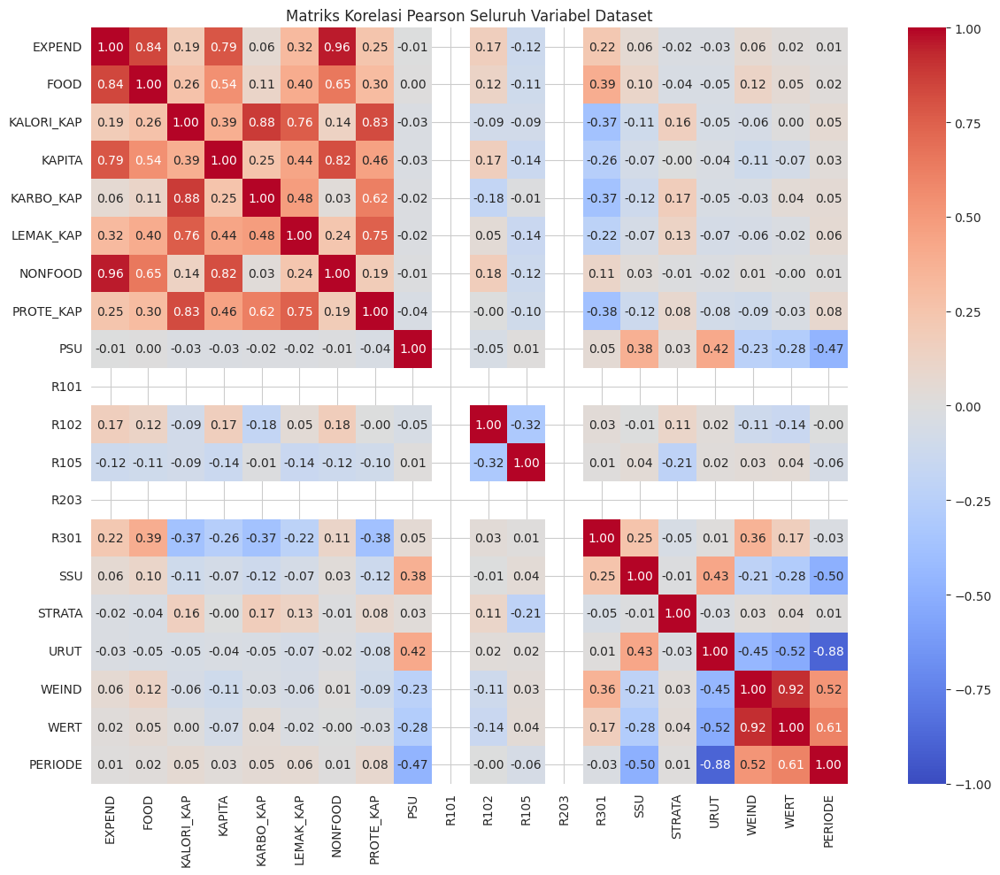


=== PASANGAN FITUR DENGAN KORELASI PEARSON > 0.8 (berpotensi redundan) ===
EXPEND <-> FOOD (r = 0.838)
EXPEND <-> NONFOOD (r = 0.960)
KALORI_KAP <-> KARBO_KAP (r = 0.881)
KALORI_KAP <-> PROTE_KAP (r = 0.825)
KAPITA <-> NONFOOD (r = 0.818)
URUT <-> PERIODE (r = -0.885)
WEIND <-> WERT (r = 0.922)

=== HASIL RANKING FILTER METHOD ===
 Peringkat   Variabel  ANOVA_F_Score  Mutual_Information  Skor_Gabungan  Selisih_ke_Berikutnya
         1     KAPITA     394.726583            0.201007       0.747880               0.091448
         2 KALORI_KAP     796.206154            0.062888       0.656431               0.007055
         3  PROTE_KAP     744.804717            0.073028       0.649377               0.170282
         4  LEMAK_KAP     547.286307            0.054437       0.479094               0.049047
         5  KARBO_KAP     536.847754            0.037354       0.430047               0.091567
         6       FOOD     349.152917            0.047928       0.338480               0.004215
 

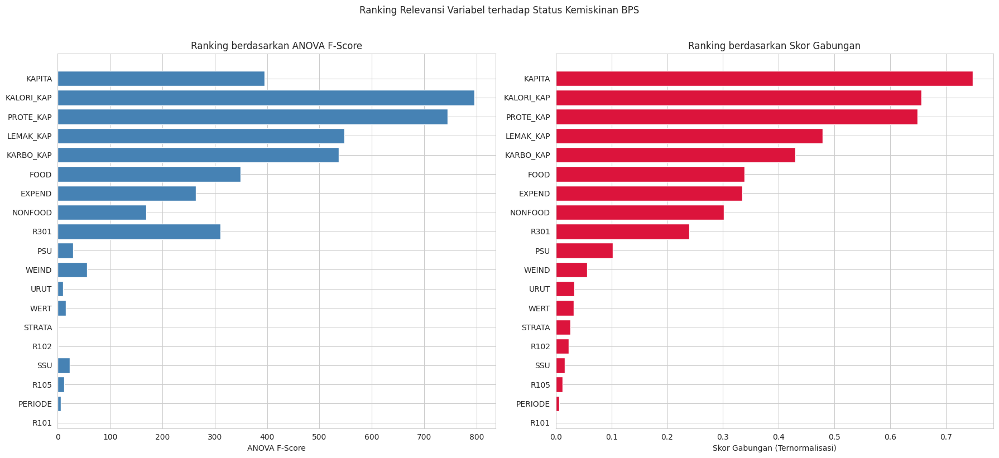

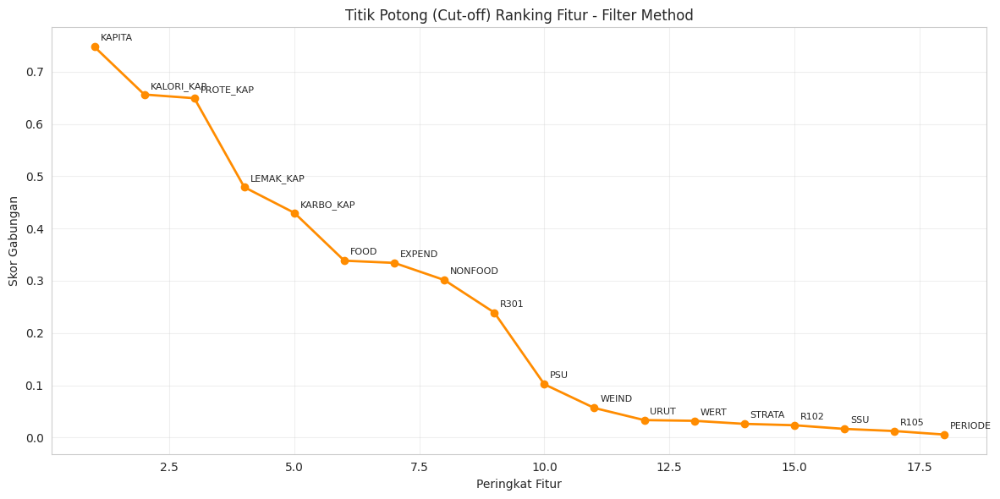


Penurunan skor paling tajam terjadi setelah peringkat 3
-> Fitur teratas yang dipertahankan: ['KAPITA', 'KALORI_KAP', 'PROTE_KAP']


In [ ]:
# ==========================================
# SELEKSI FITUR BERBASIS ALGORITMA (FILTER METHOD - 20 VARIABEL)
# ==========================================

# 1. Identifikasi seluruh variabel dataset
semua_kolom = df.columns.tolist()
kolom_non_fitur = ['status_biner', 'nama_kabkota', 'garis_kemiskinan', 'Cluster', 'label_cluster']
kandidat_20_fitur = [col for col in semua_kolom if col not in kolom_non_fitur]

df_seleksi = df.dropna(subset=kandidat_20_fitur + ['status_biner']).copy()
print(f"Jumlah variabel yang diuji : {len(kandidat_20_fitur)} variabel")
print(f"Jumlah observasi          : {len(df_seleksi)} rumah tangga")

# ------------------------------------------
# 3.1 Matriks Korelasi Pearson
# ------------------------------------------
plt.figure(figsize=(14, 10))
corr_matrix = df_seleksi[kandidat_20_fitur].corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, square=True)
plt.title('Matriks Korelasi Pearson Seluruh Variabel Dataset')
plt.tight_layout()
plt.show()

print("\n=== PASANGAN FITUR DENGAN KORELASI PEARSON > 0.8 (berpotensi redundan) ===")
ambang = 0.8
ditemukan = False
for i in range(len(kandidat_20_fitur)):
    for j in range(i+1, len(kandidat_20_fitur)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > ambang:
            print(f"{kandidat_20_fitur[i]} <-> {kandidat_20_fitur[j]} (r = {r:.3f})")
            ditemukan = True
if not ditemukan:
    print("Tidak ditemukan pasangan dengan korelasi melebihi ambang batas.")

# ------------------------------------------
# 3.2 ANOVA F-Score & Mutual Information
# ------------------------------------------
X_20 = df_seleksi[kandidat_20_fitur].values
y_target = (df_seleksi['status_biner'] == 'Miskin').astype(int).values  # 1: Miskin, 0: Tidak Miskin

f_scores, p_values = f_classif(X_20, y_target)
mi_scores = mutual_info_classif(X_20, y_target, random_state=42)

hasil_filter = pd.DataFrame({
    'Variabel': kandidat_20_fitur,
    'ANOVA_F_Score': f_scores,
    'p_value': p_values,
    'Mutual_Information': mi_scores
})

hasil_filter['F_Score_norm'] = hasil_filter['ANOVA_F_Score'] / hasil_filter['ANOVA_F_Score'].max()
hasil_filter['MI_norm'] = hasil_filter['Mutual_Information'] / hasil_filter['Mutual_Information'].max()
hasil_filter['Skor_Gabungan'] = (hasil_filter['F_Score_norm'] + hasil_filter['MI_norm']) / 2

hasil_filter = hasil_filter.sort_values('Skor_Gabungan', ascending=False).reset_index(drop=True)
hasil_filter.insert(0, 'Peringkat', range(1, len(hasil_filter) + 1))
hasil_filter['Selisih_ke_Berikutnya'] = hasil_filter['Skor_Gabungan'].diff(-1).abs()

print("\n=== HASIL RANKING FILTER METHOD ===")
print(hasil_filter[['Peringkat', 'Variabel', 'ANOVA_F_Score', 'Mutual_Information', 'Skor_Gabungan', 'Selisih_ke_Berikutnya']].to_string(index=False))

# ------------------------------------------
# 3.3 Visualisasi Ranking & Cut-off
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].barh(hasil_filter['Variabel'], hasil_filter['ANOVA_F_Score'], color='steelblue')
axes[0].invert_yaxis(); axes[0].set_xlabel('ANOVA F-Score'); axes[0].set_title('Ranking berdasarkan ANOVA F-Score')
axes[1].barh(hasil_filter['Variabel'], hasil_filter['Skor_Gabungan'], color='crimson')
axes[1].invert_yaxis(); axes[1].set_xlabel('Skor Gabungan (Ternormalisasi)'); axes[1].set_title('Ranking berdasarkan Skor Gabungan')
plt.suptitle('Ranking Relevansi Variabel terhadap Status Kemiskinan BPS', y=1.02)
plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 6))
plt.plot(hasil_filter['Peringkat'], hasil_filter['Skor_Gabungan'], marker='o', linewidth=2, color='darkorange')
for i, row in hasil_filter.iterrows():
    plt.annotate(row['Variabel'], (row['Peringkat'], row['Skor_Gabungan']),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel('Peringkat Fitur'); plt.ylabel('Skor Gabungan')
plt.title('Titik Potong (Cut-off) Ranking Fitur - Filter Method')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ------------------------------------------
# 3.4 Penetapan Otomatis Fitur Terpilih
# ------------------------------------------
titik_potong = hasil_filter['Selisih_ke_Berikutnya'].idxmax() + 1
fitur_terpilih = hasil_filter['Variabel'].head(titik_potong).tolist()

print(f"\nPenurunan skor paling tajam terjadi setelah peringkat {titik_potong}")
print(f"-> Fitur teratas yang dipertahankan: {fitur_terpilih}")

## 4. Penetapan Fitur Final Berdasarkan Hasil Filter Method

In [ ]:
# Fitur final ditetapkan OTOMATIS berdasarkan titik potong (cut-off) hasil Filter Method di Bagian 3
fitur_final_mentah = hasil_filter['Variabel'].head(titik_potong).tolist()

print(f"Fitur final (hasil Filter Method): {fitur_final_mentah}")
print(f"Dasar ilmiah: {titik_potong} fitur ini menempati peringkat teratas berdasarkan ANOVA F-Score")
print(f"dan Mutual Information terhadap status kemiskinan resmi BPS, dengan penurunan skor")
print(f"paling tajam terjadi tepat setelah peringkat ke-{titik_potong}.")

df_model = df.dropna(subset=fitur_final_mentah + ['status_biner', 'nama_kabkota']).copy()
print(f"\nJumlah baris untuk clustering: {len(df_model)}")

Fitur final (hasil Filter Method): ['KAPITA', 'KALORI_KAP', 'PROTE_KAP']
Dasar ilmiah: 3 fitur ini menempati peringkat teratas berdasarkan ANOVA F-Score
dan Mutual Information terhadap status kemiskinan resmi BPS, dengan penurunan skor
paling tajam terjadi tepat setelah peringkat ke-3.

Jumlah baris untuk clustering: 8684


## 5. Penanganan Outlier — Deteksi & Penghapusan (Metode IQR)

Outlier dideteksi **per fitur final** memakai metode IQR standar:
batas bawah = Q1 − 1.5×IQR, batas atas = Q3 + 1.5×IQR.
Baris yang outlier pada **salah satu saja** dari fitur final akan dibuang dari data pemodelan.

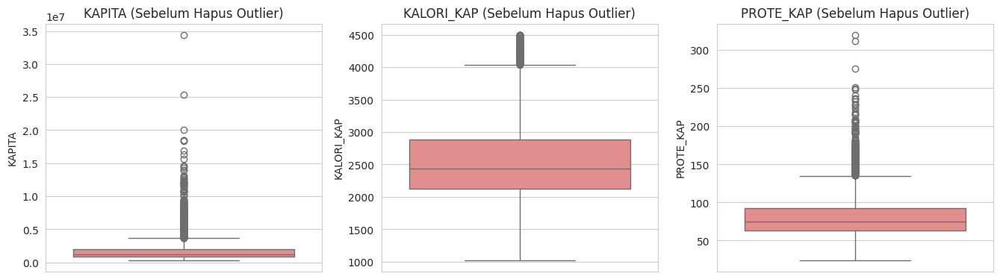

=== BATAS OUTLIER (METODE IQR) PER FITUR FINAL ===
KAPITA      : Q1=812,541.00 | Q3=1,974,026.00 | IQR=1,161,485.00 | batas=[-929,686.50 , 3,716,253.50] | outlier=647 baris
KALORI_KAP  : Q1=2,124.00 | Q3=2,889.00 | IQR=765.00 | batas=[976.50 , 4,036.50] | outlier=222 baris
PROTE_KAP   : Q1=63.00 | Q3=92.00 | IQR=29.00 | batas=[19.50 , 135.50] | outlier=338 baris

Jumlah baris SEBELUM penghapusan outlier : 8684
Jumlah baris SESUDAH penghapusan outlier : 7747
Jumlah baris dibuang                     : 937 (10.79%)


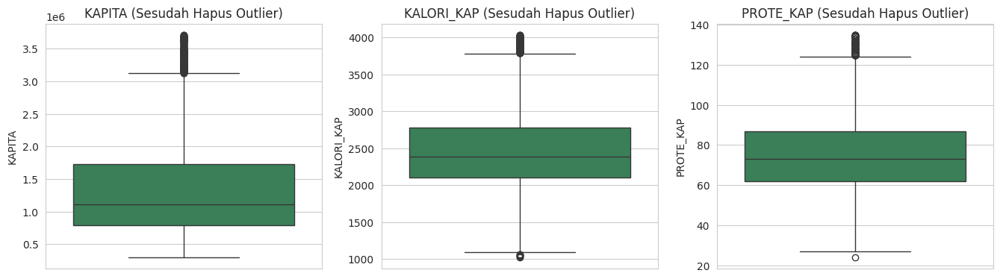

In [ ]:
# ==========================================
# DETEKSI & PENGHAPUSAN OUTLIER (METODE IQR, PER FITUR FINAL)
# ==========================================
n_sebelum = len(df_model)

# Visualisasi SEBELUM penghapusan
fig, axes = plt.subplots(1, len(fitur_final_mentah), figsize=(4.5*len(fitur_final_mentah), 4))
if len(fitur_final_mentah) == 1:
    axes = [axes]
for i, col in enumerate(fitur_final_mentah):
    sns.boxplot(y=df_model[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(f"{col} (Sebelum Hapus Outlier)")
plt.tight_layout(); plt.show()

batas_outlier = {}
mask_outlier_total = pd.Series(False, index=df_model.index)

print("=== BATAS OUTLIER (METODE IQR) PER FITUR FINAL ===")
for col in fitur_final_mentah:
    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    batas_outlier[col] = (batas_bawah, batas_atas)

    mask_col = (df_model[col] < batas_bawah) | (df_model[col] > batas_atas)
    jumlah_outlier_col = mask_col.sum()
    mask_outlier_total = mask_outlier_total | mask_col

    print(f"{col:12s}: Q1={Q1:,.2f} | Q3={Q3:,.2f} | IQR={IQR:,.2f} | "
          f"batas=[{batas_bawah:,.2f} , {batas_atas:,.2f}] | outlier={jumlah_outlier_col} baris")

# Buang seluruh baris yang outlier pada minimal satu fitur final
df_model = df_model.loc[~mask_outlier_total].copy()

n_sesudah = len(df_model)
n_dibuang = n_sebelum - n_sesudah
print(f"\nJumlah baris SEBELUM penghapusan outlier : {n_sebelum}")
print(f"Jumlah baris SESUDAH penghapusan outlier : {n_sesudah}")
print(f"Jumlah baris dibuang                     : {n_dibuang} ({n_dibuang/n_sebelum*100:.2f}%)")

# Visualisasi SESUDAH penghapusan
fig, axes = plt.subplots(1, len(fitur_final_mentah), figsize=(4.5*len(fitur_final_mentah), 4))
if len(fitur_final_mentah) == 1:
    axes = [axes]
for i, col in enumerate(fitur_final_mentah):
    sns.boxplot(y=df_model[col], ax=axes[i], color='seagreen')
    axes[i].set_title(f"{col} (Sesudah Hapus Outlier)")
plt.tight_layout(); plt.show()

## 6. Praproses Data — Log-Transform & Scaling

Variabel moneter (KAPITA/FOOD/NONFOOD/EXPEND, jika ada di antara fitur final) di-log-transform (`log1p`) agar distribusinya tidak terlalu menjulur (skewed). Variabel non-moneter (misalnya KALORI_KAP, PROTE_KAP, dll.) dipakai apa adanya. Sebagai perbandingan singkat, StandardScaler dan RobustScaler diuji dengan Silhouette Score (k=2) untuk memastikan pemilihan scaler.

Fitur final yang dipakai untuk pemodelan (setelah log-transform): ['KAPITA_log', 'KALORI_KAP', 'PROTE_KAP']


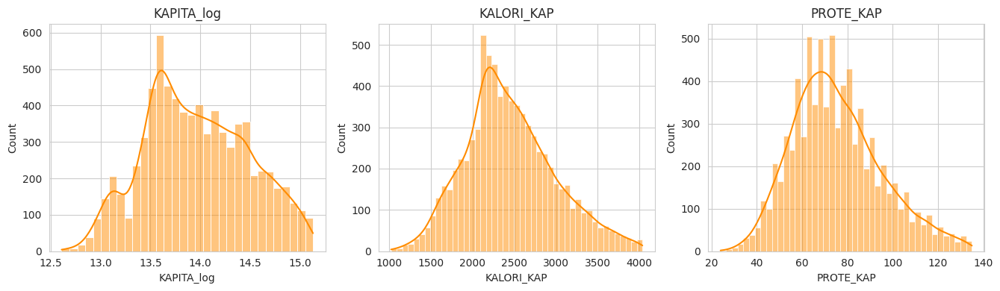


Silhouette k=2 - StandardScaler : 0.4081
Silhouette k=2 - RobustScaler   : 0.4179

-> Scaler final yang dipakai: RobustScaler


In [ ]:
# Kolom moneter (log-transform) vs non-moneter (dipakai apa adanya)
kolom_moneter = [c for c in fitur_final_mentah if c in ['KAPITA', 'FOOD', 'NONFOOD', 'EXPEND']]
kolom_non_moneter = [c for c in fitur_final_mentah if c not in kolom_moneter]

for col in kolom_moneter:
    df_model[f'{col}_log'] = np.log1p(df_model[col])

fitur_final = [f'{c}_log' for c in kolom_moneter] + kolom_non_moneter
print(f"Fitur final yang dipakai untuk pemodelan (setelah log-transform): {fitur_final}")

# Visualisasi distribusi fitur setelah log-transform
fig, axes = plt.subplots(1, len(fitur_final), figsize=(4.5*len(fitur_final), 4))
if len(fitur_final) == 1:
    axes = [axes]
for i, col in enumerate(fitur_final):
    sns.histplot(df_model[col], kde=True, ax=axes[i], color='darkorange')
    axes[i].set_title(f"{col}")
plt.tight_layout(); plt.show()

X_data = df_model[fitur_final].values

# Perbandingan singkat StandardScaler vs RobustScaler (k=2, sebagai justifikasi pemilihan scaler)
X_std_test = StandardScaler().fit_transform(X_data)
sil_std = silhouette_score(X_std_test, KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_std_test))

X_rob_test = RobustScaler().fit_transform(X_data)
sil_rob = silhouette_score(X_rob_test, KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_rob_test))

print(f"\nSilhouette k=2 - StandardScaler : {sil_std:.4f}")
print(f"Silhouette k=2 - RobustScaler   : {sil_rob:.4f}")

# RobustScaler dipilih sebagai scaler final (lebih tahan terhadap outlier/skewness sisa)
X_scaled = RobustScaler().fit_transform(X_data)
print("\n-> Scaler final yang dipakai: RobustScaler")

## 7. Reduksi Dimensi dengan PCA

PCA diterapkan pada data yang sudah di-scaling untuk (a) mengurangi redundansi antar fitur yang berkorelasi, dan (b) memudahkan visualisasi 2D. Jumlah komponen dipilih otomatis agar mencakup minimal 90% variansi data.

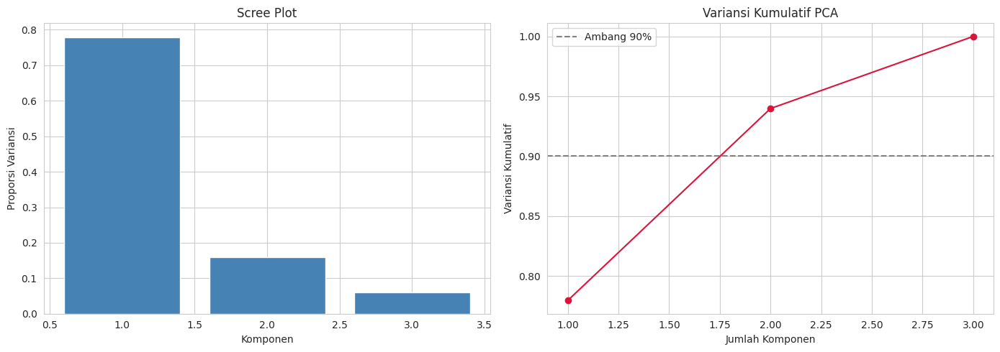

Jumlah komponen PCA terpilih : 2 (menjelaskan 93.98% variansi)
Dimensi data final untuk clustering: (7747, 2)

Kontribusi fitur pada PC1 (explained variance = 77.95%):
PROTE_KAP     0.647
KALORI_KAP    0.646
KAPITA_log    0.406

Kontribusi fitur pada PC2 (explained variance = 16.03%):
KAPITA_log    0.903
KALORI_KAP   -0.391
PROTE_KAP    -0.177


In [ ]:
# Scree plot: variansi yang dijelaskan tiap komponen
pca_full = PCA(random_state=42).fit(X_scaled)
variansi_kumulatif = np.cumsum(pca_full.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(pca_full.explained_variance_ratio_)+1), pca_full.explained_variance_ratio_, color='steelblue')
axes[0].set_xlabel('Komponen'); axes[0].set_ylabel('Proporsi Variansi'); axes[0].set_title('Scree Plot')
axes[1].plot(range(1, len(variansi_kumulatif)+1), variansi_kumulatif, marker='o', color='crimson')
axes[1].axhline(0.90, color='gray', linestyle='--', label='Ambang 90%')
axes[1].set_xlabel('Jumlah Komponen'); axes[1].set_ylabel('Variansi Kumulatif'); axes[1].set_title('Variansi Kumulatif PCA')
axes[1].legend()
plt.tight_layout(); plt.show()

# Pilih jumlah komponen otomatis (minimal 90% variansi, minimal 2 komponen untuk visualisasi)
pca_final = PCA(n_components=0.90, random_state=42)
X_final = pca_final.fit_transform(X_scaled)
n_komponen = X_final.shape[1]

print(f"Jumlah komponen PCA terpilih : {n_komponen} (menjelaskan {variansi_kumulatif[n_komponen-1]*100:.2f}% variansi)")
print(f"Dimensi data final untuk clustering: {X_final.shape}")

for i in range(n_komponen):
    kontribusi = pd.Series(pca_final.components_[i], index=fitur_final).sort_values(key=abs, ascending=False)
    print(f"\nKontribusi fitur pada PC{i+1} (explained variance = {pca_final.explained_variance_ratio_[i]*100:.2f}%):")
    print(kontribusi.round(3).to_string())

## 8. Penentuan Jumlah Klaster Optimal (pada Data Hasil PCA)

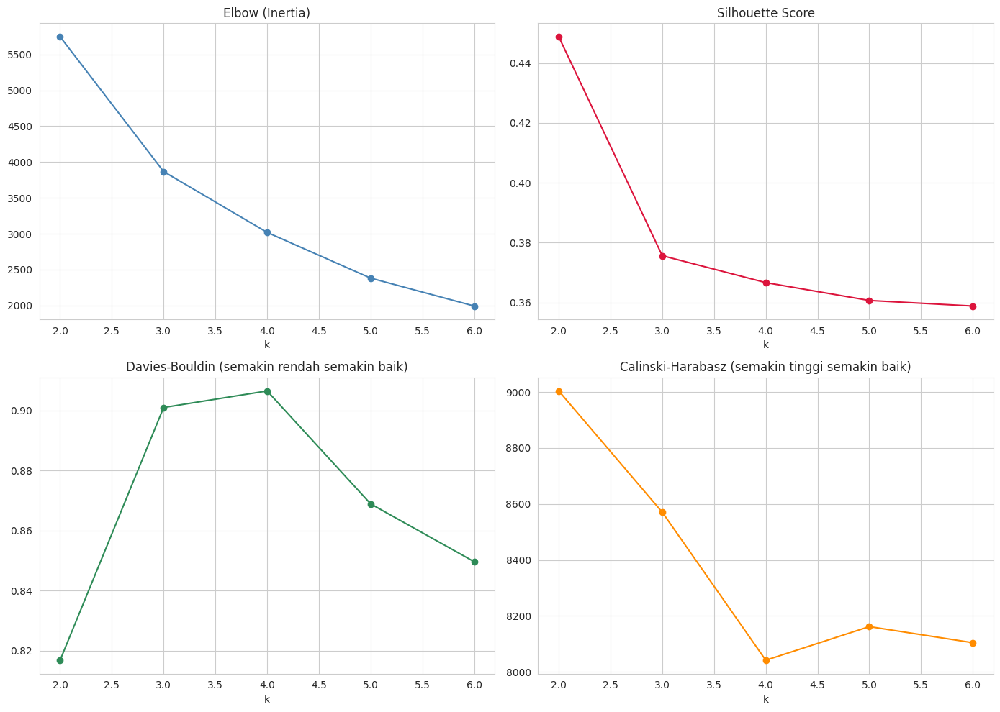

 k  Silhouette  Davies_Bouldin  Calinski_Harabasz
 2    0.448800        0.816877        9004.102583
 3    0.375665        0.901026        8570.591508
 4    0.366669        0.906549        8041.615042
 5    0.360707        0.868941        8161.711298
 6    0.358851        0.849688        8104.225286

Rekomendasi k berdasarkan Silhouette tertinggi: k = 2


In [ ]:
inertia, silhouette_scores, db_scores, ch_scores = [], [], [], []
k_range = range(2, 7)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_final)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_final, labels))
    db_scores.append(davies_bouldin_score(X_final, labels))
    ch_scores.append(calinski_harabasz_score(X_final, labels))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0,0].plot(list(k_range), inertia, marker='o', color='steelblue'); axes[0,0].set_title('Elbow (Inertia)')
axes[0,1].plot(list(k_range), silhouette_scores, marker='o', color='crimson'); axes[0,1].set_title('Silhouette Score')
axes[1,0].plot(list(k_range), db_scores, marker='o', color='seagreen'); axes[1,0].set_title('Davies-Bouldin (semakin rendah semakin baik)')
axes[1,1].plot(list(k_range), ch_scores, marker='o', color='darkorange'); axes[1,1].set_title('Calinski-Harabasz (semakin tinggi semakin baik)')
for ax in axes.flatten(): ax.set_xlabel('k')
plt.tight_layout(); plt.show()

ringkasan_k = pd.DataFrame({'k': list(k_range), 'Silhouette': silhouette_scores,
                             'Davies_Bouldin': db_scores, 'Calinski_Harabasz': ch_scores})
print(ringkasan_k.to_string(index=False))

K_OPTIMAL = list(k_range)[int(np.argmax(silhouette_scores))]
print(f"\nRekomendasi k berdasarkan Silhouette tertinggi: k = {K_OPTIMAL}")

## 9. K-Means Clustering Final

In [ ]:
kmeans_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
df_model['cluster'] = kmeans_final.fit_predict(X_final)

# Beri label deskriptif berdasarkan urutan rata-rata KAPITA (semakin rendah = semakin miskin)
urutan_klaster_by_kapita = df_model.groupby('cluster')['KAPITA'].mean().sort_values().index.tolist()
if K_OPTIMAL == 2:
    nama_label = ['Cenderung Miskin', 'Cenderung Tidak Miskin']
elif K_OPTIMAL == 3:
    nama_label = ['Konsumsi Rendah', 'Konsumsi Menengah', 'Konsumsi Tinggi']
else:
    nama_label = [f'Level {i+1}' for i in range(K_OPTIMAL)]
label_map = dict(zip(urutan_klaster_by_kapita, nama_label))
df_model['label_cluster'] = df_model['cluster'].map(label_map)

print(f"Clustering selesai dengan k={K_OPTIMAL}")
print(df_model['label_cluster'].value_counts())

Clustering selesai dengan k=2
label_cluster
Cenderung Miskin          4612
Cenderung Tidak Miskin    3135
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

# 1. Jalankan K-Means utama untuk mendapatkan n_iter_ optimal
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
df_model['cluster'] = kmeans_final.fit_predict(X_final)
total_iter = kmeans_final.n_iter_

print(f"=== K-MEANS KONVERGEN DALAM {total_iter} ITERASI ===\n")

# 2. Loop untuk merekam pergeseran centroid dari iterasi 1 sampai konvergen
history_centroids = []
for i in range(1, total_iter + 1):
    km_step = KMeans(n_clusters=2, init='k-means++', n_init=1, max_iter=i, random_state=42)
    km_step.fit(X_final)
    history_centroids.append(km_step.cluster_centers_)

    c0 = km_step.cluster_centers_[0]
    c1 = km_step.cluster_centers_[1]
    print(f"Iterasi {i}:")
    print(f"  Centroid Klaster 0: PC1 = {c0[0]:.4f}, PC2 = {c0[1]:.4f}")
    print(f"  Centroid Klaster 1: PC1 = {c1[0]:.4f}, PC2 = {c1[1]:.4f}")
    print("-" * 50)

=== K-MEANS KONVERGEN DALAM 9 ITERASI ===

Iterasi 1:
  Centroid Klaster 0: PC1 = 1.5655, PC2 = -0.0630
  Centroid Klaster 1: PC1 = -0.5024, PC2 = 0.0202
--------------------------------------------------
Iterasi 2:
  Centroid Klaster 0: PC1 = 1.3848, PC2 = -0.0444
  Centroid Klaster 1: PC1 = -0.6023, PC2 = 0.0193
--------------------------------------------------
Iterasi 3:
  Centroid Klaster 0: PC1 = 1.2838, PC2 = -0.0207
  Centroid Klaster 1: PC1 = -0.6632, PC2 = 0.0107
--------------------------------------------------
Iterasi 4:
  Centroid Klaster 0: PC1 = 1.2204, PC2 = -0.0062
  Centroid Klaster 1: PC1 = -0.7032, PC2 = 0.0036
--------------------------------------------------
Iterasi 5:
  Centroid Klaster 0: PC1 = 1.1815, PC2 = 0.0003
  Centroid Klaster 1: PC1 = -0.7286, PC2 = -0.0002
--------------------------------------------------
Iterasi 6:
  Centroid Klaster 0: PC1 = 1.1586, PC2 = 0.0038
  Centroid Klaster 1: PC1 = -0.7438, PC2 = -0.0024
------------------------------------

In [ ]:
# 1. Inisialisasi dan jalankan model K-Means Final
kmeans_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
df_model['cluster'] = kmeans_final.fit_predict(X_final)

# 2. Tampilkan jumlah iterasi dan koordinat centroid akhir
print("=" * 60)
print(f"Clustering selesai dengan k={K_OPTIMAL}")
print(f"Jumlah Iterasi hingga Konvergen (Optimal): {kmeans_final.n_iter_} kali")
print("-" * 60)

print("Koordinat Centroid Akhir (pada Ruang PCA):")
for i, center in enumerate(kmeans_final.cluster_centers_):
    print(f"  Centroid Klaster {i}: PC1 = {center[0]:.4f}, PC2 = {center[1]:.4f}")
print("=" * 60)

# 3. Beri label deskriptif berdasarkan urutan rata-rata KAPITA (semakin rendah = semakin miskin)
urutan_klaster_by_kapita = df_model.groupby('cluster')['KAPITA'].mean().sort_values().index.tolist()
if K_OPTIMAL == 2:
    nama_label = ['Cenderung Miskin', 'Cenderung Tidak Miskin']
elif K_OPTIMAL == 3:
    nama_label = ['Konsumsi Rendah', 'Konsumsi Menengah', 'Konsumsi Tinggi']
else:
    nama_label = [f'Level {i+1}' for i in range(K_OPTIMAL)]

label_map = dict(zip(urutan_klaster_by_kapita, nama_label))
df_model['label_cluster'] = df_model['cluster'].map(label_map)

# 4. Tampilkan sebaran jumlah anggota tiap klaster
print("\nSebaran Jumlah Anggota Klaster:")
print(df_model['label_cluster'].value_counts())

Clustering selesai dengan k=2
Jumlah Iterasi hingga Konvergen (Optimal): 9 kali
------------------------------------------------------------
Koordinat Centroid Akhir (pada Ruang PCA):
  Centroid Klaster 0: PC1 = 1.1303, PC2 = 0.0067
  Centroid Klaster 1: PC1 = -0.7630, PC2 = -0.0045

Sebaran Jumlah Anggota Klaster:
label_cluster
Cenderung Miskin          4612
Cenderung Tidak Miskin    3135
Name: count, dtype: int64


## UNTUK MENGECEK DAN MENAMPILKAN KLASTER CENDERUNG MISKIN YANG BENAR2 URGENT DENGAN KAPITA, KALORI_KAP DAN PROTE_KAPNYA SAMA2 RENDAH

In [ ]:
# Contoh: mengecek label mana yang merupakan klaster miskin (misal label 0 atau 1)
print("Distribusi data per klaster:")
print(df_model['cluster'].value_counts())

# Berdasarkan profil rata-rata KAPITA di notebook Anda, klaster 1 adalah kelompok 'Cenderung Miskin'
LABEL_MISKIN = 1

df_miskin = df_model[df_model['cluster'] == LABEL_MISKIN]

# Menggunakan median dari klaster miskin sebagai batas "benar-benar rendah"
limit_kapita = df_miskin['KAPITA'].quantile(0.5)
limit_kalori = df_miskin['KALORI_KAP'].quantile(0.5)
limit_protekap = df_miskin['PROTE_KAP'].quantile(0.5)

# Melakukan filter
df_benar_rendah = df_miskin[
    (df_miskin['KAPITA'] <= limit_kapita) &
    (df_miskin['KALORI_KAP'] <= limit_kalori) &
    (df_miskin['PROTE_KAP'] <= limit_protekap)
]

print(f"\nJumlah rumah tangga deprivasi ganda (benar-benar rendah): {len(df_benar_rendah)} rumah tangga")
print(f"Persentase dari total klaster miskin: {(len(df_benar_rendah) / len(df_miskin)) * 100:.2f}%")

# Menampilkan sampel data teratas
display(df_benar_rendah[['R102', 'KAPITA', 'KALORI_KAP', 'PROTE_KAP']].head(10))

Distribusi data per klaster:
cluster
1    4612
0    3135
Name: count, dtype: int64

Jumlah rumah tangga deprivasi ganda (benar-benar rendah): 1165 rumah tangga
Persentase dari total klaster miskin: 25.26%


,R102,KAPITA,KALORI_KAP,PROTE_KAP
5,8,602009,1932,46
7,4,753792,2108,61
13,8,649845,2032,49
14,2,473113,2013,55
33,71,698053,2124,50
39,1,392726,1883,47
43,6,616931,1891,51
45,71,501680,1306,37
97,6,399958,1604,48
100,2,363083,1643,33


In [ ]:
import pandas as pd

# 1. Mengatur pandas agar menampilkan seluruh baris tanpa terpotong (tidak ada batasan max_rows)
pd.set_option('display.max_rows', None)

# Cek distribusi data per klaster
print("Distribusi data per klaster:")
print(df_model['cluster'].value_counts())

# Tentukan label klaster miskin (sesuai notebook Anda yaitu 1)
LABEL_MISKIN = 1
df_miskin = df_model[df_model['cluster'] == LABEL_MISKIN]

# Tentukan batas "benar-benar rendah" menggunakan median di dalam klaster miskin
limit_kapita = df_miskin['KAPITA'].quantile(0.5)
limit_kalori = df_miskin['KALORI_KAP'].quantile(0.5)
limit_protekap = df_miskin['PROTE_KAP'].quantile(0.5)

# Melakukan filter rumah tangga deprivasi ganda
df_benar_rendah = df_miskin[
    (df_miskin['KAPITA'] <= limit_kapita) &
    (df_miskin['KALORI_KAP'] <= limit_kalori) &
    (df_miskin['PROTE_KAP'] <= limit_protekap)
]

print(f"\nTotal rumah tangga deprivasi ganda (benar-benar rendah): {len(df_benar_rendah)} rumah tangga")
print(f"Persentase dari total klaster miskin: {(len(df_benar_rendah) / len(df_miskin)) * 100:.2f}%\n")

print("="*60)
print(" BAGIAN 1: RINCIAN LENGKAP SELURUH RUMAH TANGGA URGENT")
print("="*60)
# Menampilkan seluruh baris data rincian (Kolom R102 mewakili wilayah/Kabupaten)
display(df_benar_rendah[['R102', 'KAPITA', 'KALORI_KAP', 'PROTE_KAP']])

print("\n" + "="*60)
print(" BAGIAN 2: RANGKUMAN TOTAL RUMAH TANGGA URGENT PER KABUPATEN/KOTA")
print("="*60)
# Membuat tabel rangkuman jumlah rumah tangga per kabupaten/kota
summary_kab = df_benar_rendah['R102'].value_counts().reset_index()
summary_kab.columns = ['Kabupaten_Kota (R102)', 'Jumlah_RT_Urgent']

# Urutkan berdasarkan jumlah terbanyak agar mudah dianalisis untuk laporan
summary_kab = summary_kab.sort_values(by='Jumlah_RT_Urgent', ascending=False).reset_index(drop=True)

display(summary_kab)

# (Opsional) Kembalikan setting max_rows pandas ke default agar notebook tidak terlalu panjang ke bawah di cell selanjutnya
# pd.reset_option('display.max_rows')

Distribusi data per klaster:
cluster
1    4612
0    3135
Name: count, dtype: int64

Total rumah tangga deprivasi ganda (benar-benar rendah): 1165 rumah tangga
Persentase dari total klaster miskin: 25.26%

 BAGIAN 1: RINCIAN LENGKAP SELURUH RUMAH TANGGA URGENT


,R102,KAPITA,KALORI_KAP,PROTE_KAP
5,8,602009,1932,46
7,4,753792,2108,61
13,8,649845,2032,49
14,2,473113,2013,55
33,71,698053,2124,50
39,1,392726,1883,47
43,6,616931,1891,51
45,71,501680,1306,37
97,6,399958,1604,48
100,2,363083,1643,33



 BAGIAN 2: RANGKUMAN TOTAL RUMAH TANGGA URGENT PER KABUPATEN/KOTA


,Kabupaten_Kota (R102),Jumlah_RT_Urgent
0,6,189
1,4,174
2,1,171
3,2,169
4,72,121
5,5,120
6,71,71
7,8,56
8,7,48
9,3,46


In [ ]:
import pandas as pd

# 1. Mengatur pandas agar menampilkan seluruh baris tanpa terpotong
pd.set_option('display.max_rows', None)

# Cek distribusi data per klaster
print("Distribusi data per klaster:")
print(df_model['cluster'].value_counts())

# Tentukan label klaster miskin (sesuai notebook Anda yaitu 1)
LABEL_MISKIN = 1
df_miskin = df_model[df_model['cluster'] == LABEL_MISKIN]

# Tentukan batas "benar-benar rendah" menggunakan median di dalam klaster miskin
limit_kapita = df_miskin['KAPITA'].quantile(0.5)
limit_kalori = df_miskin['KALORI_KAP'].quantile(0.5)
limit_protekap = df_miskin['PROTE_KAP'].quantile(0.5)

# Melakukan filter rumah tangga deprivasi ganda
df_benar_rendah = df_miskin[
    (df_miskin['KAPITA'] <= limit_kapita) &
    (df_miskin['KALORI_KAP'] <= limit_kalori) &
    (df_miskin['PROTE_KAP'] <= limit_protekap)
].copy() # Menggunakan .copy() agar aman dari SettingWithCopyWarning

# ==========================================
# KAMUS PEMETAAN KODE KABUPATEN/KOTA NTB (R102)
# ==========================================
# (Pastikan tipe data R102 di dataframe Anda berupa string/integer yang cocok)
mapping_kab = {
    1: 'Lombok Barat',
    2: 'Lombok Tengah',
    3: 'Lombok Timur',
    4: 'Sumbawa',
    5: 'Dompu',
    6: 'Bima',
    7: 'Sumbawa Barat',
    8: 'Lombok Utara',
    71: 'Kota Mataram',
    72: 'Kota Bima'
    # Jika di data Anda berupa string (misal '5201'), ubah key di atas menjadi string ('5201': 'Lombok Barat')
}

# Membuat kolom baru 'NAMA_KABUPATEN' berdasarkan kolom R102
df_benar_rendah['NAMA_KABUPATEN'] = df_benar_rendah['R102'].map(mapping_kab)

print(f"\nTotal rumah tangga deprivasi ganda (benar-benar rendah): {len(df_benar_rendah)} rumah tangga")
print(f"Persentase dari total klaster miskin: {(len(df_benar_rendah) / len(df_miskin)) * 100:.2f}%\n")

print("="*70)
print(" BAGIAN 1: RINCIAN LENGKAP SELURUH RUMAH TANGGA URGENT + NAMA KABUPATEN")
print("="*70)
# Menampilkan kolom R102, Nama Kabupaten, beserta variabel utamanya
display(df_benar_rendah[['R102', 'NAMA_KABUPATEN', 'KAPITA', 'KALORI_KAP', 'PROTE_KAP']])

print("\n" + "="*70)
print(" BAGIAN 2: RANGKUMAN TOTAL RUMAH TANGGA URGENT PER KABUPATEN/KOTA")
print("="*70)
# Membuat tabel rangkuman jumlah rumah tangga berdasarkan Nama Kabupaten
summary_kab = df_benar_rendah['NAMA_KABUPATEN'].value_counts().reset_index()
summary_kab.columns = ['Nama_Kabupaten_Kota', 'Jumlah_RT_Urgent']

# Urutkan berdasarkan jumlah terbanyak
summary_kab = summary_kab.sort_values(by='Jumlah_RT_Urgent', ascending=False).reset_index(drop=True)

display(summary_kab)

Distribusi data per klaster:
cluster
1    4612
0    3135
Name: count, dtype: int64

Total rumah tangga deprivasi ganda (benar-benar rendah): 1165 rumah tangga
Persentase dari total klaster miskin: 25.26%

 BAGIAN 1: RINCIAN LENGKAP SELURUH RUMAH TANGGA URGENT + NAMA KABUPATEN


,R102,NAMA_KABUPATEN,KAPITA,KALORI_KAP,PROTE_KAP
5,8,Lombok Utara,602009,1932,46
7,4,Sumbawa,753792,2108,61
13,8,Lombok Utara,649845,2032,49
14,2,Lombok Tengah,473113,2013,55
33,71,Kota Mataram,698053,2124,50
39,1,Lombok Barat,392726,1883,47
43,6,Bima,616931,1891,51
45,71,Kota Mataram,501680,1306,37
97,6,Bima,399958,1604,48
100,2,Lombok Tengah,363083,1643,33



 BAGIAN 2: RANGKUMAN TOTAL RUMAH TANGGA URGENT PER KABUPATEN/KOTA


,Nama_Kabupaten_Kota,Jumlah_RT_Urgent
0,Bima,189
1,Sumbawa,174
2,Lombok Barat,171
3,Lombok Tengah,169
4,Kota Bima,121
5,Dompu,120
6,Kota Mataram,71
7,Lombok Utara,56
8,Sumbawa Barat,48
9,Lombok Timur,46


## 10. Evaluasi Kualitas Klaster

=== METRIK EVALUASI KLASTER FINAL ===
Silhouette Score      : 0.4488
Davies-Bouldin Index  : 0.8169
Calinski-Harabasz     : 9004.10


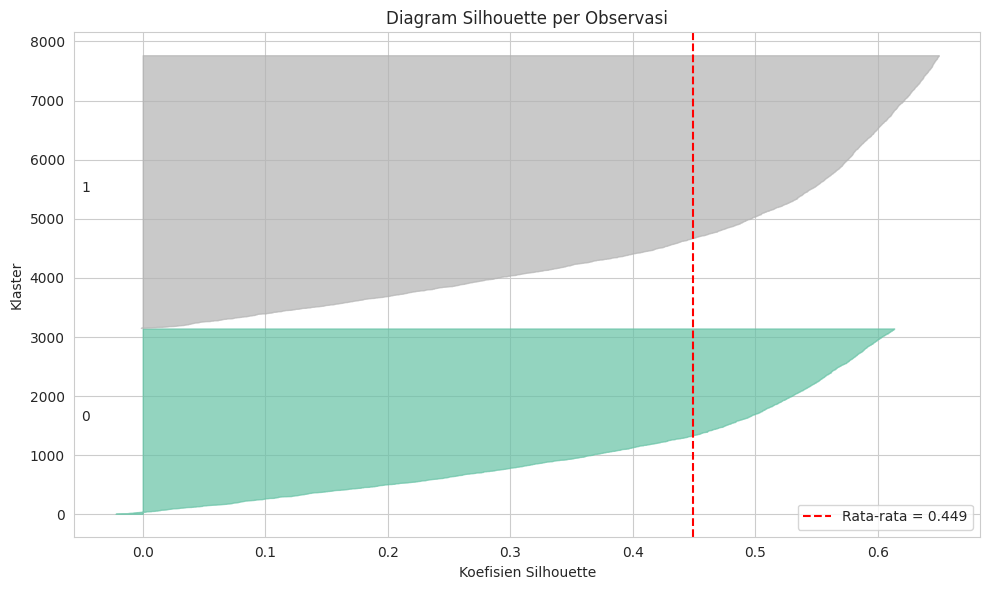

In [ ]:
sil_final = silhouette_score(X_final, df_model['cluster'])
db_final = davies_bouldin_score(X_final, df_model['cluster'])
ch_final = calinski_harabasz_score(X_final, df_model['cluster'])

print("=== METRIK EVALUASI KLASTER FINAL ===")
print(f"Silhouette Score      : {sil_final:.4f}")
print(f"Davies-Bouldin Index  : {db_final:.4f}")
print(f"Calinski-Harabasz     : {ch_final:.2f}")

sample_silhouette_values = silhouette_samples(X_final, df_model['cluster'])
fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 10
warna = plt.cm.Set2(np.linspace(0, 1, K_OPTIMAL))
for i in range(K_OPTIMAL):
    ith_values = np.sort(sample_silhouette_values[df_model['cluster'] == i])
    size_i = ith_values.shape[0]
    y_upper = y_lower + size_i
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_values, facecolor=warna[i], edgecolor=warna[i], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5*size_i, str(i))
    y_lower = y_upper + 10
ax.axvline(x=sil_final, color='red', linestyle='--', label=f'Rata-rata = {sil_final:.3f}')
ax.set_xlabel('Koefisien Silhouette'); ax.set_ylabel('Klaster'); ax.set_title('Diagram Silhouette per Observasi')
ax.legend(); plt.tight_layout(); plt.show()

## 11. Visualisasi Sebaran Data Tiap Klaster

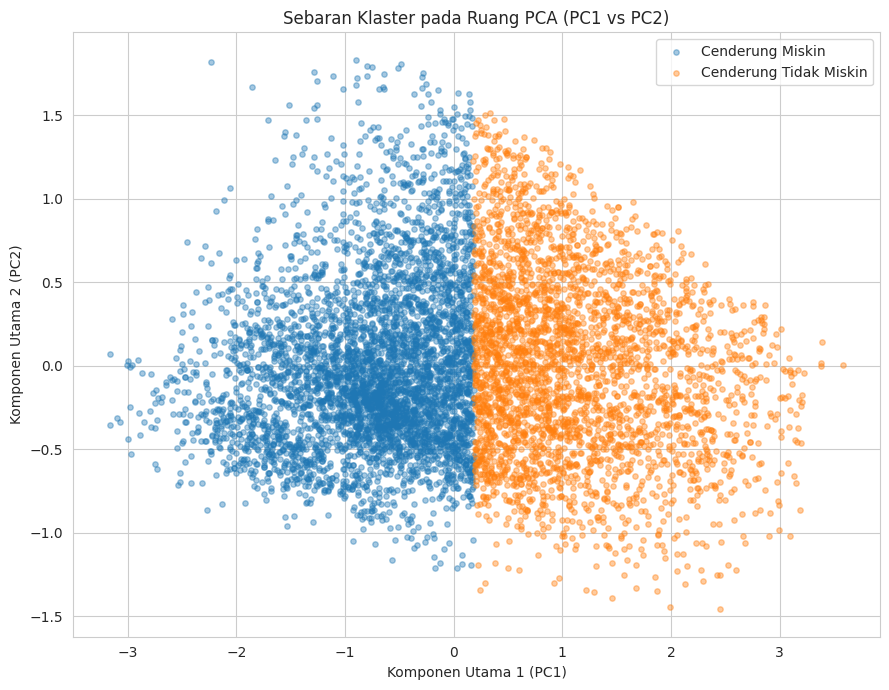

In [ ]:
# 11.1 Visualisasi klaster pada ruang PCA (2 komponen pertama)
plt.figure(figsize=(9, 7))
for label in df_model['label_cluster'].unique():
    mask = df_model['label_cluster'] == label
    plt.scatter(X_final[mask.values, 0], X_final[mask.values, 1], alpha=0.4, s=15, label=label)
plt.xlabel('Komponen Utama 1 (PC1)'); plt.ylabel('Komponen Utama 2 (PC2)')
plt.title('Sebaran Klaster pada Ruang PCA (PC1 vs PC2)')
plt.legend(); plt.tight_layout(); plt.show()

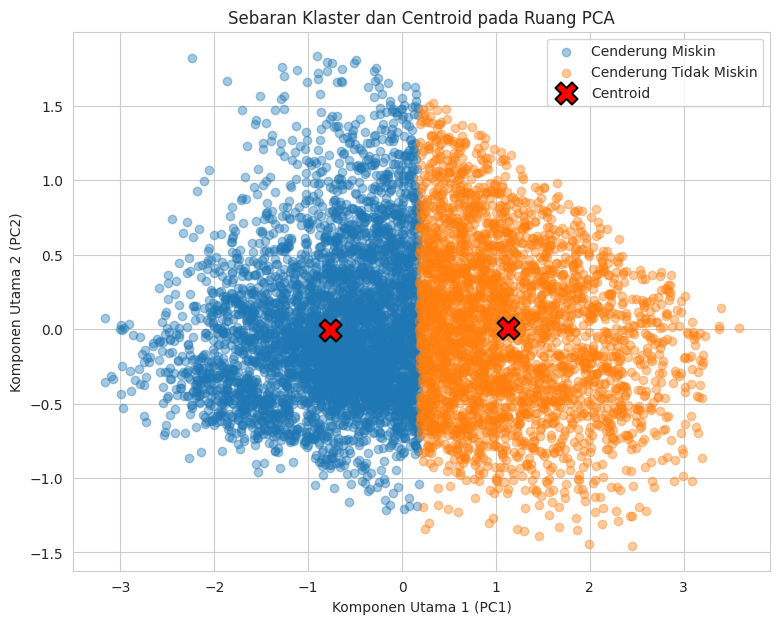

In [ ]:
# MENAMPILKAN TITIK CENTROID
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

# 1. Plot sebaran titik data
for label in df_model['label_cluster'].unique():
    mask = df_model['label_cluster'] == label
    plt.scatter(X_final[mask.values, 0], X_final[mask.values, 1], alpha=0.4, label=label)

# 2. TAMBAHKAN BARIS INI: Plot titik centroid secara khusus
centroids = kmeans_final.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=250,           # Ukuran simbol centroid
    c='red',         # Warna titik centroid
    marker='X',      # Simbol tanda 'X'
    edgecolor='black',
    linewidth=1.5,
    label='Centroid'
)

plt.xlabel('Komponen Utama 1 (PC1)')
plt.ylabel('Komponen Utama 2 (PC2)')
plt.title('Sebaran Klaster dan Centroid pada Ruang PCA')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# 1. Siapkan DataFrame untuk visualisasi
df_plot = df_model.copy()
df_plot['PC1'] = X_final[:, 0]
df_plot['PC2'] = X_final[:, 1]

# 2. Buat scatter plot interaktif untuk titik data
fig = px.scatter(
    df_plot,
    x='PC1',
    y='PC2',
    color='label_cluster',  # Mengelompokkan warna berdasarkan klaster
    hover_data={
        'PC1': False,       # Sembunyikan nilai PC1 dari tooltip jika tidak diperlukan
        'PC2': False,       # Sembunyikan nilai PC2 dari tooltip
        'KAPITA': ':,.2f',  # Tampilkan nilai KAPITA asli dengan format ribuan
        'KALORI_KAP': ':.2f',   # Tampilkan nilai KALORI_KAP asli
        'PROTE_KAP': ':.2f',    # Tampilkan nilai PROTE_KAP asli
        'label_cluster': True
    },
    opacity=0.6,
    title='Sebaran Klaster Interaktif pada Ruang PCA (Hover untuk melihat detail)'
)

# 3. Tambahkan titik Centroid (Penanda 'X' Merah)
centroids = kmeans_final.cluster_centers_
fig.add_trace(
    go.Scatter(
        x=centroids[:, 0],
        y=centroids[:, 1],
        mode='markers',
        marker=dict(
            symbol='x',
            size=15,
            color='red',
            line=dict(width=2, color='black')
        ),
        name='Centroid',
        hoverinfo='name'
    )
)

# 4. Atur tata letak grafik
fig.update_layout(
    xaxis_title='Komponen Utama 1 (PC1)',
    yaxis_title='Komponen Utama 2 (PC2)',
    template='plotly_white',
    legend_title_text='Klaster'
)

# Tampilkan grafik interaktif
fig.show()

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# 1. Mapping Kode Kabupaten/Kota BPS NTB ke Nama Wilayah
nama_kab_map = {
    1: 'Lombok Barat',
    2: 'Lombok Tengah',
    3: 'Lombok Timur',
    4: 'Sumbawa',
    5: 'Dompu',
    6: 'Bima',
    7: 'Sumbawa Barat',
    8: 'Lombok Utara',
    71: 'Kota Mataram',
    72: 'Kota Bima',
}

# 2. Siapkan DataFrame untuk visualisasi
df_plot = df_model.copy()
df_plot['PC1'] = X_final[:, 0]
df_plot['PC2'] = X_final[:, 1]

# Tambahkan kolom nama kabupaten berdasarkan kode R102
df_plot['Nama_Kabupaten'] = df_plot['R102'].map(nama_kab_map)

# 3. Buat Scatter Plot dengan Facet (Subplot per Kabupaten/Kota)
fig = px.scatter(
    df_plot,
    x='PC1',
    y='PC2',
    color='label_cluster',  # Warna berdasarkan klaster
    facet_col='Nama_Kabupaten',  # Memecah plot berdasarkan kabupaten/kota
    facet_col_wrap=5,  # Menampilkan 5 kolom per baris (2 baris total untuk 10 daerah)
    hover_data={
        'PC1': False,
        'PC2': False,
        'Nama_Kabupaten': True,
        'KAPITA': ':,.2f',
        'KALORI_KAP': ':.2f',
        'PROTE_KAP': ':.2f',
        'label_cluster': True,
    },
    opacity=0.6,
    title='Sebaran Klaster Interaktif PCA per Kabupaten/Kota di Provinsi NTB',
)

# 4. Atur layout agar tampilan rapi
fig.update_layout(
    height=700,  # Memperbesar tinggi grafik agar 10 subplot terlihat jelas
    template='plotly_white',
    legend_title_text='Klaster',
)

fig.show()

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

# 1. Mapping Kode Kabupaten/Kota BPS NTB
nama_kab_map = {
    1: 'Kab. Lombok Barat',
    2: 'Kab. Lombok Tengah',
    3: 'Kab. Lombok Timur',
    4: 'Kab. Sumbawa',
    5: 'Kab. Dompu',
    6: 'Kab. Bima',
    7: 'Kab. Sumbawa Barat',
    8: 'Kab. Lombok Utara',
    71: 'Kota Mataram',
    72: 'Kota Bima',
}

df_plot = df_model.copy()
df_plot['PC1'] = X_final[:, 0]
df_plot['PC2'] = X_final[:, 1]
df_plot['Nama_Kabupaten'] = df_plot['R102'].map(nama_kab_map)

# 2. Buat Plot dengan Menambahkan Kolom Nama_Kabupaten pada Hover Data & Symbol/Color
fig = px.scatter(
    df_plot,
    x='PC1',
    y='PC2',
    color='label_cluster',
    symbol='Nama_Kabupaten',  # Membedakan bentuk simbol per kabupaten jika dilihat serentak
    hover_name='Nama_Kabupaten',  # Menampilkan nama kabupaten di bagian paling atas tooltip hover
    hover_data={
        'PC1': False,
        'PC2': False,
        'KAPITA': ':,.2f',
        'KALORI_KAP': ':.2f',
        'PROTE_KAP': ':.2f',
        'label_cluster': True,
    },
    opacity=0.7,
    title='Sebaran Klaster Interaktif pada Ruang PCA Berdasarkan Kabupaten/Kota',
)

# 3. Tambahkan Centroid
centroids = kmeans_final.cluster_centers_
fig.add_trace(
    go.Scatter(
        x=centroids[:, 0],
        y=centroids[:, 1],
        mode='markers',
        marker=dict(
            symbol='x', size=15, color='red', line=dict(width=2, color='black')
        ),
        name='Centroid',
        hoverinfo='name',
    )
)

# 4. Tata letak grafik
fig.update_layout(
    xaxis_title='Komponen Utama 1 (PC1)',
    yaxis_title='Komponen Utama 2 (PC2)',
    template='plotly_white',
    legend_title_text='Klaster & Wilayah',
)

fig.show()

# MERINCIKAN MASING2 KABUPATEN DAN KOTA UNTUK TIAP2 KLASTERNYA

In [ ]:
import pandas as pd

# ATUR OPSI PANDAS AGAR MENAMPILKAN SEMUA BARIS (TANPA TERPOTONG)
pd.set_option('display.max_rows', None)  # Menampilkan seluruh baris tanpa batas
pd.set_option('display.max_columns', None)  # Menampilkan seluruh kolom
pd.set_option('display.width', 1000)

# 1. Mapping Kode Kabupaten/Kota BPS NTB
nama_kab_map = {
    1: 'Kab. Lombok Barat',
    2: 'Kab. Lombok Tengah',
    3: 'Kab. Lombok Timur',
    4: 'Kab. Sumbawa',
    5: 'Kab. Dompu',
    6: 'Kab. Bima',
    7: 'Kab. Sumbawa Barat',
    8: 'Kab. Lombok Utara',
    71: 'Kota Mataram',
    72: 'Kota Bima',
}

df_detail = df_model.copy()
df_detail['Nama_Kabupaten'] = df_detail['R102'].map(nama_kab_map)

# 2. Looping per Kabupaten dan per Klaster untuk menampilkan seluruh data rumah tangga
for kode_kab in sorted(df_detail['R102'].unique()):
  nama_kab = nama_kab_map.get(kode_kab, f'Kode {kode_kab}')
  df_kab = df_detail[df_detail['R102'] == kode_kab]

  print(
      f'\n============================================================\nWILAYAH:'
      f' {nama_kab} (Total Seluruh RT: {len(df_kab)})\n============================================================'
  )

  for cluster_name in sorted(df_kab['label_cluster'].unique(), reverse=True):
    sub_df = df_kab[df_kab['label_cluster'] == cluster_name]
    print(
        f' > Klaster: {cluster_name} | Jumlah Sampel: {len(sub_df)} Rumah'
        ' Tangga'
    )

    # Menampilkan seluruh baris individu tanpa ada yang disembunyikan/terpotong
    display(
        sub_df[[
            'R102',
            'Nama_Kabupaten',
            'label_cluster',
            'KAPITA',
            'KALORI_KAP',
            'PROTE_KAP',
        ]].reset_index(drop=True)
    )


WILAYAH: Kab. Lombok Barat (Total Seluruh RT: 890)
 > Klaster: Cenderung Tidak Miskin | Jumlah Sampel: 321 Rumah Tangga


,R102,Nama_Kabupaten,label_cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1748976,3584,101
1,1,Kab. Lombok Barat,Cenderung Tidak Miskin,962996,2651,80
2,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1403829,3420,99
3,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1359787,2584,75
4,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1504638,2771,112
5,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1707947,3772,91
6,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1919005,2564,85
7,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1544178,2784,93
8,1,Kab. Lombok Barat,Cenderung Tidak Miskin,1562547,2695,95
9,1,Kab. Lombok Barat,Cenderung Tidak Miskin,2327541,3330,135


 > Klaster: Cenderung Miskin | Jumlah Sampel: 569 Rumah Tangga


,R102,Nama_Kabupaten,label_cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,1,Kab. Lombok Barat,Cenderung Miskin,1042984,2474,65
1,1,Kab. Lombok Barat,Cenderung Miskin,924138,2109,74
2,1,Kab. Lombok Barat,Cenderung Miskin,1736684,2538,69
3,1,Kab. Lombok Barat,Cenderung Miskin,1010358,2245,70
4,1,Kab. Lombok Barat,Cenderung Miskin,1314383,2186,58
5,1,Kab. Lombok Barat,Cenderung Miskin,1157459,1910,60
6,1,Kab. Lombok Barat,Cenderung Miskin,392726,1883,47
7,1,Kab. Lombok Barat,Cenderung Miskin,1615246,2004,55
8,1,Kab. Lombok Barat,Cenderung Miskin,812464,2385,63
9,1,Kab. Lombok Barat,Cenderung Miskin,1014407,2318,61



WILAYAH: Kab. Lombok Tengah (Total Seluruh RT: 984)
 > Klaster: Cenderung Tidak Miskin | Jumlah Sampel: 408 Rumah Tangga


...

,R102,Nama_Kabupaten,label_cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,71,Kota Mataram,Cenderung Miskin,1198289,2436,75
1,71,Kota Mataram,Cenderung Miskin,898215,2238,65
2,71,Kota Mataram,Cenderung Miskin,698053,2124,50
3,71,Kota Mataram,Cenderung Miskin,501680,1306,37
4,71,Kota Mataram,Cenderung Miskin,2096583,2093,77
5,71,Kota Mataram,Cenderung Miskin,679672,1946,61
6,71,Kota Mataram,Cenderung Miskin,792214,2196,61
7,71,Kota Mataram,Cenderung Miskin,864321,1762,44
8,71,Kota Mataram,Cenderung Miskin,810314,2203,62
9,71,Kota Mataram,Cenderung Miskin,1415398,2474,70



WILAYAH: Kota Bima (Total Seluruh RT: 590)
 > Klaster: Cenderung Tidak Miskin | Jumlah Sampel: 188 Rumah Tangga


,R102,Nama_Kabupaten,label_cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,72,Kota Bima,Cenderung Tidak Miskin,2259800,3193,113
1,72,Kota Bima,Cenderung Tidak Miskin,2446198,2557,81
2,72,Kota Bima,Cenderung Tidak Miskin,1519208,2546,75
3,72,Kota Bima,Cenderung Tidak Miskin,2160279,2498,91
4,72,Kota Bima,Cenderung Tidak Miskin,2441784,2578,75
5,72,Kota Bima,Cenderung Tidak Miskin,1703872,2585,100
6,72,Kota Bima,Cenderung Tidak Miskin,2361678,2287,75
7,72,Kota Bima,Cenderung Tidak Miskin,1909815,3661,111
8,72,Kota Bima,Cenderung Tidak Miskin,1397095,2805,88
9,72,Kota Bima,Cenderung Tidak Miskin,2408439,2749,81


 > Klaster: Cenderung Miskin | Jumlah Sampel: 402 Rumah Tangga


,R102,Nama_Kabupaten,label_cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,72,Kota Bima,Cenderung Miskin,979796,2266,59
1,72,Kota Bima,Cenderung Miskin,543411,1610,48
2,72,Kota Bima,Cenderung Miskin,807718,2483,86
3,72,Kota Bima,Cenderung Miskin,1145397,1632,59
4,72,Kota Bima,Cenderung Miskin,2095261,2079,66
5,72,Kota Bima,Cenderung Miskin,1173925,1868,58
6,72,Kota Bima,Cenderung Miskin,624783,2113,57
7,72,Kota Bima,Cenderung Miskin,909420,1743,49
8,72,Kota Bima,Cenderung Miskin,1311472,2387,81
9,72,Kota Bima,Cenderung Miskin,787316,2167,67


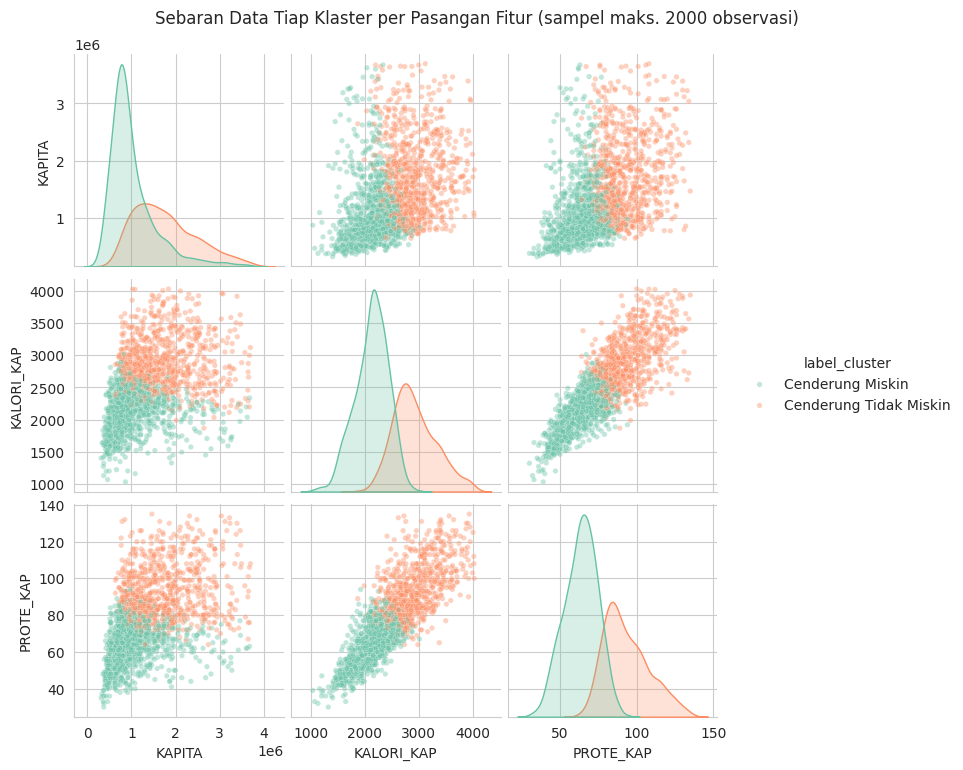

In [ ]:
# 11.2 Pairplot sebaran data asli (bukan hasil scaling/PCA) per klaster
sample_plot = df_model.sample(min(2000, len(df_model)), random_state=42)
pairplot_data = sample_plot[fitur_final_mentah + ['label_cluster']]

g = sns.pairplot(pairplot_data, hue='label_cluster', palette='Set2',
                  diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15})
g.fig.suptitle('Sebaran Data Tiap Klaster per Pasangan Fitur (sampel maks. 2000 observasi)', y=1.02)
plt.show()

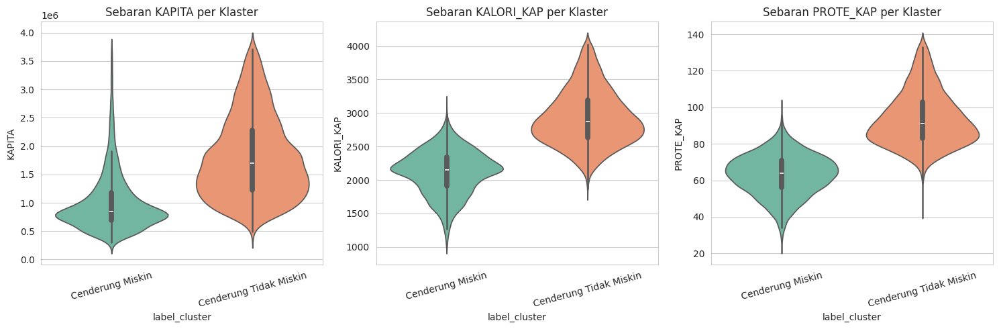

In [ ]:
# 11.3 Violin plot - distribusi tiap fitur final per klaster
fig, axes = plt.subplots(1, len(fitur_final_mentah), figsize=(5*len(fitur_final_mentah), 5))
if len(fitur_final_mentah) == 1:
    axes = [axes]
for i, col in enumerate(fitur_final_mentah):
    sns.violinplot(data=df_model, x='label_cluster', y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Sebaran {col} per Klaster')
    axes[i].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 12. Karakterisasi Klaster — Profil Statistik & Rincian Range Tiap Fitur

Bagian ini memberikan **rincian range (interval nilai)** setiap klaster untuk setiap fitur final, mencakup nilai minimum, kuartil 1 (Q1), median, rata-rata, kuartil 3 (Q3), dan maksimum — dihitung dari **nilai asli** (bukan hasil log-transform/scaling/PCA) agar mudah diinterpretasikan.

In [ ]:
profil_klaster = df_model.groupby('label_cluster')[fitur_final_mentah].agg(['mean', 'median', 'std']).round(1)
print("=== PROFIL STATISTIK TIAP KLASTER (mean, median, std) ===")
print(profil_klaster)

ukuran = df_model['label_cluster'].value_counts()
ukuran_persen = (ukuran / len(df_model) * 100).round(2)
print("\n=== UKURAN TIAP KLASTER ===")
for label in ukuran.index:
    print(f"{label}: {ukuran[label]} rumah tangga ({ukuran_persen[label]}%)")

=== PROFIL STATISTIK TIAP KLASTER (mean, median, std) ===
                           KAPITA                      KALORI_KAP          \
                             mean     median       std       mean  median   
label_cluster                                                               
Cenderung Miskin        1007838.8   847924.0  522461.6     2117.4  2150.0   
Cenderung Tidak Miskin  1803679.4  1696318.0  716198.3     2931.1  2876.0   

                              PROTE_KAP               
                          std      mean median   std  
label_cluster                                         
Cenderung Miskin        326.0      63.0   64.0  11.1  
Cenderung Tidak Miskin  408.3      93.7   91.0  14.7  

=== UKURAN TIAP KLASTER ===
Cenderung Miskin: 4612 rumah tangga (59.53%)
Cenderung Tidak Miskin: 3135 rumah tangga (40.47%)


In [ ]:
import pandas as pd

# 1. Gunakan df_model yang berisi hasil klasterisasi aktual
# Pastikan kita menganalisis fitur-fitur final yang digunakan untuk clustering
feature_cols = fitur_final_mentah  # ['KAPITA', 'KALORI_KAP', 'PROTE_KAP']

# 2. Hitung Nilai Min dan Max untuk setiap variabel di masing-masing klaster ('cluster' huruf kecil)
cluster_stats = df_model.groupby('cluster')[feature_cols].agg(['min', 'max'])

print("=== RENTANG MIN-MAX PER KLASTER ===")
print(cluster_stats)
print("\n" + "="*50 + "\n")

# 3. Cari rentang tumpang tindih (Overlap Range) untuk setiap variabel
overlap_conditions = []

for col in feature_cols:
    min_c0 = cluster_stats.loc[0, (col, 'min')]
    max_c0 = cluster_stats.loc[0, (col, 'max')]
    min_c1 = cluster_stats.loc[1, (col, 'min')]
    max_c1 = cluster_stats.loc[1, (col, 'max')]

    # Batas bawah overlap adalah nilai Minimum terbesar dari kedua klaster
    overlap_min = max(min_c0, min_c1)
    # Batas atas overlap adalah nilai Maksimum terkecil dari kedua klaster
    overlap_max = min(max_c0, max_c1)

    if overlap_min <= overlap_max:
        print(f"Variabel '{col}' OVERLAP pada rentang nilai: {overlap_min} s/d {overlap_max}")
        # Buat kondisi filter untuk data yang nilainya masuk di rentang overlap ini
        cond = (df_model[col] >= overlap_min) & (df_model[col] <= overlap_max)
        overlap_conditions.append(cond)
    else:
        print(f"Variabel '{col}' TIDAK OVERLAP secara nilai min-max.")

# 4. Filter data yang mengalami overlap pada SELURUH variabel sekaligus
if overlap_conditions:
    # Menggabungkan seluruh kondisi overlap variabel
    combined_overlap_cond = pd.concat(overlap_conditions, axis=1).all(axis=1)
    df_overlap = df_model[combined_overlap_cond]

    print("\n" + "="*50)
    print(f"TOTAL DATA YANG TUMPANG TINDIH (OVERLAP): {len(df_overlap)} observasi")
    print("="*50)

    # 5. Tampilkan sampel data yang overlap
    print("\nContoh Data yang Overlap (Menampilkan 10 data pertama):")
    display(df_overlap[['nama_kabkota', 'label_cluster'] + feature_cols].head(10))

=== RENTANG MIN-MAX PER KLASTER ===
         KAPITA          KALORI_KAP       PROTE_KAP     
            min      max        min   max       min  max
cluster                                                 
0        491066  3712884       1867  4035        45  135
1        299705  3696369       1024  3131        24  100


Variabel 'KAPITA' OVERLAP pada rentang nilai: 491066 s/d 3696369
Variabel 'KALORI_KAP' OVERLAP pada rentang nilai: 1867 s/d 3131
Variabel 'PROTE_KAP' OVERLAP pada rentang nilai: 45 s/d 100

TOTAL DATA YANG TUMPANG TINDIH (OVERLAP): 5322 observasi

Contoh Data yang Overlap (Menampilkan 10 data pertama):


,nama_kabkota,label_cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,Sumbawa,Cenderung Miskin,1117312,2152,71
2,Lombok Barat,Cenderung Miskin,1042984,2474,65
3,Lombok Barat,Cenderung Miskin,924138,2109,74
5,Lombok Utara,Cenderung Miskin,602009,1932,46
6,Lombok Barat,Cenderung Miskin,1736684,2538,69
7,Sumbawa,Cenderung Miskin,753792,2108,61
8,Lombok Utara,Cenderung Miskin,1084297,2538,65
9,Lombok Utara,Cenderung Miskin,1618162,2357,69
13,Lombok Utara,Cenderung Miskin,649845,2032,49
17,Lombok Barat,Cenderung Tidak Miskin,962996,2651,80


In [ ]:
import pandas as pd

feature_cols = fitur_final_mentah  # ['KAPITA', 'KALORI_KAP', 'PROTE_KAP']

# 1. Hitung Nilai Min dan Max per klaster
cluster_stats = df_model.groupby('cluster')[feature_cols].agg(['min', 'max'])

print("=== RENTANG MIN-MAX PER KLASTER ===")
print(cluster_stats)
print("\n" + "="*60 + "\n")

# 2. Cari kondisi overlap untuk setiap variabel
overlap_conditions = []

for col in feature_cols:
    min_c0 = cluster_stats.loc[0, (col, 'min')]
    max_c0 = cluster_stats.loc[0, (col, 'max')]
    min_c1 = cluster_stats.loc[1, (col, 'min')]
    max_c1 = cluster_stats.loc[1, (col, 'max')]

    overlap_min = max(min_c0, min_c1)
    overlap_max = min(max_c0, max_c1)

    if overlap_min <= overlap_max:
        cond = (df_model[col] >= overlap_min) & (df_model[col] <= overlap_max)
        overlap_conditions.append(cond)

# 3. Gabungkan seluruh kondisi overlap
if overlap_conditions:
    combined_overlap_cond = pd.concat(overlap_conditions, axis=1).all(axis=1)
    df_overlap = df_model[combined_overlap_cond]

    # RINCIAN PER KLASTER (Penjelas ke Penguji)
    count_c0 = (df_overlap['cluster'] == 0).sum()
    count_c1 = (df_overlap['cluster'] == 1).sum()
    total_c0 = (df_model['cluster'] == 0).sum()
    total_c1 = (df_model['cluster'] == 1).sum()

    print("="*60)
    print(f"RINCIAN DATA DI AREA OVERLAP (NILAI VARIABEL DENGAN IRISAN SAMA):")
    print(f"• Dari Klaster 0 : {count_c0} data (dari total {total_c0} data Klaster 0)")
    print(f"• Dari Klaster 1 : {count_c1} data (dari total {total_c1} data Klaster 1)")
    print(f"• TOTAL COMBINED  : {len(df_overlap)} data (gabungan kedua klaster)")
    print("="*60)

    # Tampilkan sampel data
    display(df_overlap[['nama_kabkota', 'cluster'] + feature_cols].head(10))

=== RENTANG MIN-MAX PER KLASTER ===
         KAPITA          KALORI_KAP       PROTE_KAP     
            min      max        min   max       min  max
cluster                                                 
0        491066  3712884       1867  4035        45  135
1        299705  3696369       1024  3131        24  100


RINCIAN DATA DI AREA OVERLAP (NILAI VARIABEL DENGAN IRISAN SAMA):
• Dari Klaster 0 : 1853 data (dari total 3135 data Klaster 0)
• Dari Klaster 1 : 3469 data (dari total 4612 data Klaster 1)
• TOTAL COMBINED  : 5322 data (gabungan kedua klaster)


,nama_kabkota,cluster,KAPITA,KALORI_KAP,PROTE_KAP
0,Sumbawa,1,1117312,2152,71
2,Lombok Barat,1,1042984,2474,65
3,Lombok Barat,1,924138,2109,74
5,Lombok Utara,1,602009,1932,46
6,Lombok Barat,1,1736684,2538,69
7,Sumbawa,1,753792,2108,61
8,Lombok Utara,1,1084297,2538,65
9,Lombok Utara,1,1618162,2357,69
13,Lombok Utara,1,649845,2032,49
17,Lombok Barat,0,962996,2651,80


In [ ]:
# ==========================================
# RINCIAN RANGE (INTERVAL NILAI) TIAP KLASTER, PER FITUR FINAL
# ==========================================
kolom_moneter_set = {'KAPITA', 'FOOD', 'NONFOOD', 'EXPEND'}

def format_nilai(fitur, nilai):
    if fitur in kolom_moneter_set:
        return f"Rp {nilai:,.0f}".replace(',', '.')
    return f"{nilai:,.2f}"

daftar_range = []
for label in sorted(df_model['label_cluster'].unique()):
    sub = df_model[df_model['label_cluster'] == label]
    for fitur in fitur_final_mentah:
        vals = sub[fitur]
        daftar_range.append({
            'Klaster': label,
            'Fitur': fitur,
            'Min': vals.min(),
            'Q1 (25%)': vals.quantile(0.25),
            'Median': vals.median(),
            'Mean': vals.mean(),
            'Q3 (75%)': vals.quantile(0.75),
            'Max': vals.max(),
            'Range (Min - Max)': f"{format_nilai(fitur, vals.min())}  s.d.  {format_nilai(fitur, vals.max())}"
        })

range_df = pd.DataFrame(daftar_range)
print("=== TABEL RINCIAN RANGE TIAP KLASTER PER FITUR FINAL ===")
print(range_df.round(2).to_string(index=False))

print("\n\n=== RINCIAN NARATIF PER KLASTER ===")
for label in sorted(df_model['label_cluster'].unique()):
    sub = df_model[df_model['label_cluster'] == label]
    n = len(sub)
    print(f"\nKlaster: {label}  (n = {n} rumah tangga, {n/len(df_model)*100:.2f}% dari total)")
    for fitur in fitur_final_mentah:
        vals = sub[fitur]
        print(f"  - {fitur:12s}: range {format_nilai(fitur, vals.min())} s.d. {format_nilai(fitur, vals.max())} "
              f"| Q1={format_nilai(fitur, vals.quantile(0.25))} | median={format_nilai(fitur, vals.median())} "
              f"| Q3={format_nilai(fitur, vals.quantile(0.75))} | mean={format_nilai(fitur, vals.mean())}")

# Tampilan pivot ringkas: Klaster (baris) x Fitur (kolom) -> string Range
pivot_range = range_df.pivot(index='Klaster', columns='Fitur', values='Range (Min - Max)')
print("\n\n=== RINGKASAN RANGE (PIVOT: KLASTER x FITUR) ===")
print(pivot_range.to_string())

=== TABEL RINCIAN RANGE TIAP KLASTER PER FITUR FINAL ===
               Klaster      Fitur    Min   Q1 (25%)    Median       Mean  Q3 (75%)     Max              Range (Min - Max)
      Cenderung Miskin     KAPITA 299705  690351.50  847924.0 1007838.76 1179923.5 3696369 Rp 299.705  s.d.  Rp 3.696.369
      Cenderung Miskin KALORI_KAP   1024    1911.75    2150.0    2117.40    2343.0    3131       1,024.00  s.d.  3,131.00
      Cenderung Miskin  PROTE_KAP     24      56.00      64.0      63.00      71.0     100            24.00  s.d.  100.00
Cenderung Tidak Miskin     KAPITA 491066 1230561.00 1696318.0 1803679.37 2275430.5 3712884 Rp 491.066  s.d.  Rp 3.712.884
Cenderung Tidak Miskin KALORI_KAP   1867    2635.00    2876.0    2931.09    3192.0    4035       1,867.00  s.d.  4,035.00
Cenderung Tidak Miskin  PROTE_KAP     45      83.00      91.0      93.74     103.0     135            45.00  s.d.  135.00


=== RINCIAN NARATIF PER KLASTER ===

Klaster: Cenderung Miskin  (n = 4612 rumah tangga,

In [ ]:
# ==========================================
# EKSPOR DATA AKHIR + VERIFIKASI OTOMATIS (ANTI-MISMATCH)
# ==========================================
kolom_identitas = ['nama_kabkota']
kolom_export = kolom_identitas + fitur_final_mentah + ['cluster', 'label_cluster']
df_final_ringkas = df_model[kolom_export].copy()

# Verifikasi LANGSUNG dari data yang akan diekspor (bukan dari output lama)
print("=== RANGE AKTUAL PADA DATA YANG AKAN DIEKSPOR (dijamin sinkron) ===")
print(df_final_ringkas.groupby('label_cluster')[fitur_final_mentah].agg(['min', 'max']))

nama_file_ringkas = 'data_final_klaster_fitur_terpakai.xlsx'
df_final_ringkas.to_excel(nama_file_ringkas, index=False)
print(f"\nBerhasil diekspor ke '{nama_file_ringkas}' — angka di atas adalah angka yang PERSIS ada di file ini.")
files.download(nama_file_ringkas)

=== RANGE AKTUAL PADA DATA YANG AKAN DIEKSPOR (dijamin sinkron) ===
                        KAPITA          KALORI_KAP       PROTE_KAP     
                           min      max        min   max       min  max
label_cluster                                                          
Cenderung Miskin        299705  3696369       1024  3131        24  100
Cenderung Tidak Miskin  491066  3712884       1867  4035        45  135

Berhasil diekspor ke 'data_final_klaster_fitur_terpakai.xlsx' — angka di atas adalah angka yang PERSIS ada di file ini.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

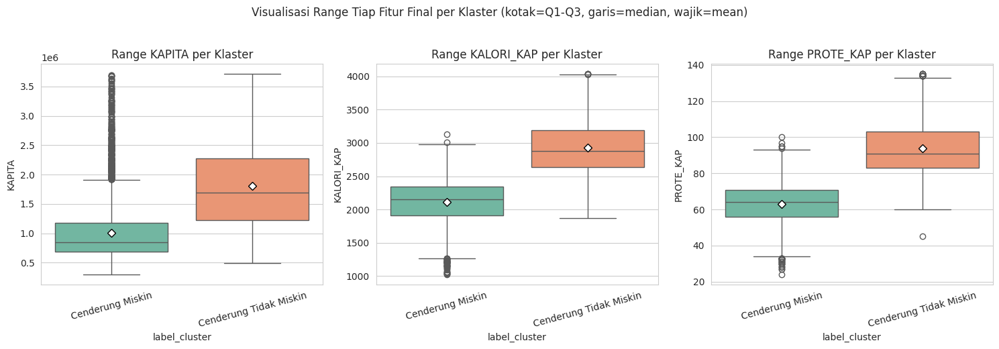

In [ ]:
# Visualisasi range: boxplot per fitur (garis tengah = median, kotak = Q1-Q3, whisker = min/max efektif)
fig, axes = plt.subplots(1, len(fitur_final_mentah), figsize=(5*len(fitur_final_mentah), 5))
if len(fitur_final_mentah) == 1:
    axes = [axes]
for i, col in enumerate(fitur_final_mentah):
    sns.boxplot(data=df_model, x='label_cluster', y=col, ax=axes[i], palette='Set2', showmeans=True,
                meanprops={'marker':'D', 'markerfacecolor':'white', 'markeredgecolor':'black'})
    axes[i].set_title(f'Range {col} per Klaster')
    axes[i].tick_params(axis='x', rotation=15)
plt.suptitle('Visualisasi Range Tiap Fitur Final per Klaster (kotak=Q1-Q3, garis=median, wajik=mean)', y=1.03)
plt.tight_layout(); plt.show()

## 13. Uji Kruskal-Wallis Antar Klaster

In [ ]:
print("=== UJI KRUSKAL-WALLIS PER VARIABEL ANTAR KLASTER ===")
hasil_uji = []
for var in fitur_final_mentah:
    grup = [df_model[df_model['cluster'] == k][var].dropna() for k in sorted(df_model['cluster'].unique())]
    stat, p_value = kruskal(*grup)
    ket = "Signifikan (p<0.05)" if p_value < 0.05 else "Tidak Signifikan"
    hasil_uji.append({'Variabel': var, 'Statistik_H': round(stat, 2), 'p_value': f"{p_value:.2e}", 'Keterangan': ket})
hasil_uji_df = pd.DataFrame(hasil_uji)
print(hasil_uji_df.to_string(index=False))

=== UJI KRUSKAL-WALLIS PER VARIABEL ANTAR KLASTER ===
  Variabel  Statistik_H  p_value          Keterangan
    KAPITA      2650.20 0.00e+00 Signifikan (p<0.05)
KALORI_KAP      4619.20 0.00e+00 Signifikan (p<0.05)
 PROTE_KAP      4944.73 0.00e+00 Signifikan (p<0.05)


## 14. Profil Kabupaten/Kota

=== PROPORSI KEANGGOTAAN KLASTER PER KABUPATEN/KOTA (%) ===
label_cluster  Cenderung Miskin  Cenderung Tidak Miskin
nama_kabkota                                           
Bima                      64.99                   35.01
Dompu                     61.92                   38.08
Kota Bima                 68.14                   31.86
Kota Mataram              57.00                   43.00
Lombok Barat              63.93                   36.07
Lombok Tengah             58.54                   41.46
Lombok Timur              40.71                   59.29
Lombok Utara              53.37                   46.63
Sumbawa                   71.90                   28.10
Sumbawa Barat             61.72                   38.28


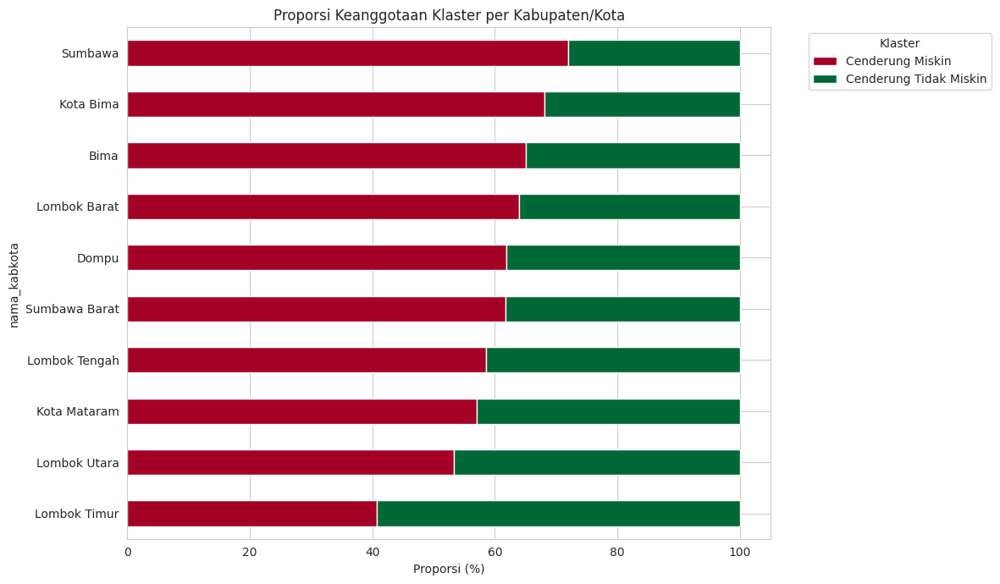

In [ ]:
profil_wilayah = pd.crosstab(df_model['nama_kabkota'], df_model['label_cluster'], normalize='index') * 100
profil_wilayah = profil_wilayah.round(2)
print("=== PROPORSI KEANGGOTAAN KLASTER PER KABUPATEN/KOTA (%) ===")
print(profil_wilayah)

fig, ax = plt.subplots(figsize=(12, 7))
profil_wilayah.sort_values(by=profil_wilayah.columns[0]).plot(kind='barh', stacked=True, ax=ax, colormap='RdYlGn')
ax.set_xlabel('Proporsi (%)'); ax.set_title('Proporsi Keanggotaan Klaster per Kabupaten/Kota')
ax.legend(title='Klaster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()

=== JUMLAH KEANGGOTAAN KLASTER PER KABUPATEN/KOTA (JUMLAH RT) ===
label_cluster  Cenderung Miskin  Cenderung Tidak Miskin  Total
nama_kabkota                                                  
Bima                        529                     285    814
Dompu                       444                     273    717
Kota Bima                   402                     188    590
Kota Mataram                387                     292    679
Lombok Barat                569                     321    890
Lombok Tengah               576                     408    984
Lombok Timur                412                     600   1012
Lombok Utara                380                     332    712
Sumbawa                     568                     222    790
Sumbawa Barat               345                     214    559


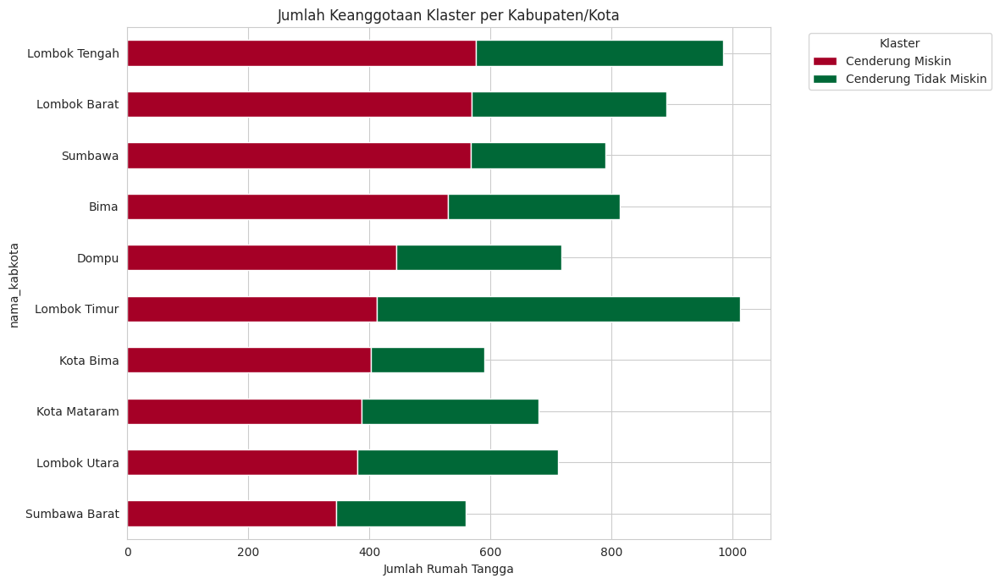

In [ ]:
# 1. Menghitung jumlah riil (frekuensi) rumah tangga per kabupaten/kota
profil_wilayah_counts = pd.crosstab(
    df_model["nama_kabkota"], df_model["label_cluster"]
)

# Menambahkan kolom Total jika ingin melihat total observasi per kabupaten/kota
profil_wilayah_counts["Total"] = profil_wilayah_counts.sum(axis=1)

print("=== JUMLAH KEANGGOTAAN KLASTER PER KABUPATEN/KOTA (JUMLAH RT) ===")
print(profil_wilayah_counts)

# 2. Visualisasi Stacked Bar Chart berdasarkan Jumlah Riil
fig, ax = plt.subplots(figsize=(12, 7))

# Menghilangkan kolom 'Total' saat membuat plot agar tidak mengacaukan grafik
kolom_klaster = [col for col in profil_wilayah_counts.columns if col != "Total"]

profil_wilayah_counts[kolom_klaster].sort_values(
    by=kolom_klaster[0]
).plot(kind="barh", stacked=True, ax=ax, colormap="RdYlGn")

# Penyesuaian label sumbu X dan Judul
ax.set_xlabel("Jumlah Rumah Tangga")
ax.set_title("Jumlah Keanggotaan Klaster per Kabupaten/Kota")
ax.legend(title="Klaster", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

## 15. Ringkasan Hasil

In [ ]:
print("="*70)
print("RINGKASAN HASIL — VERSI A — PENANGANAN OUTLIER (DIHAPUS, METODE IQR) + PCA")
print("="*70)
print(f"""
Jumlah fitur final          : {len(fitur_final_mentah)} ({fitur_final_mentah})
Jumlah observasi dipakai    : {len(df_model)}
Jumlah komponen PCA         : {n_komponen} (variansi dijelaskan: {variansi_kumulatif[n_komponen-1]*100:.2f}%)
k optimal (Silhouette)      : {K_OPTIMAL}

Evaluasi Klaster:
  Silhouette Score     : {sil_final:.4f}
  Davies-Bouldin Index : {db_final:.4f}
  Calinski-Harabasz    : {ch_final:.2f}
""")

RINGKASAN HASIL — VERSI A — PENANGANAN OUTLIER (DIHAPUS, METODE IQR) + PCA

Jumlah fitur final          : 3 (['KAPITA', 'KALORI_KAP', 'PROTE_KAP'])
Jumlah observasi dipakai    : 7747
Jumlah komponen PCA         : 2 (variansi dijelaskan: 93.98%)
k optimal (Silhouette)      : 2

Evaluasi Klaster:
  Silhouette Score     : 0.4488
  Davies-Bouldin Index : 0.8169
  Calinski-Harabasz    : 9004.10



## 16. Ekspor Hasil

In [ ]:
with pd.ExcelWriter('hasil_klasterisasi_pca_hapus_outlier.xlsx', engine='openpyxl') as writer:
    df_model.to_excel(writer, sheet_name='Data + Hasil Klaster', index=False)
    profil_klaster.to_excel(writer, sheet_name='Profil Statistik Klaster')
    range_df.to_excel(writer, sheet_name='Rincian Range per Klaster', index=False)
    hasil_uji_df.to_excel(writer, sheet_name='Uji Kruskal-Wallis', index=False)
    profil_wilayah.to_excel(writer, sheet_name='Profil per Kabkota')
    ringkasan_k.to_excel(writer, sheet_name='Perbandingan Nilai k',  index=False)

print("Hasil berhasil diekspor ke 'hasil_klasterisasi_pca_hapus_outlier.xlsx'")
files.download('hasil_klasterisasi_pca_hapus_outlier.xlsx')

Hasil berhasil diekspor ke 'hasil_klasterisasi_pca_hapus_outlier.xlsx'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>